<a href="https://colab.research.google.com/github/Racsok/mineria/blob/desarrollo/Avance_2_FIFA_Mineria_Datos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/Racsok/mineria/blob/desarrollo/Avance_2_FIFA_Mineria_Datos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Avance 2 — Todo el semestre en una tabla (sin PCA)
**Proyecto:** Minería de Datos sobre el Dataset de Jugadores FIFA (`fifa_eda_stats.csv`)  
**Asignatura:** Minería de Datos 26160 — Grupo 020-81-2026-3  
**Universidad Distrital Francisco José de Caldas**

---

## Página de firmas y aportes por integrante

| Integrante | Parte del trabajo realizada | Firma / Confirmación |
|---|---|---|
| **Juan Pablo Mosquera** | *[completar]* | *[Firma]* |
| **David Zahid Riveros** | *[completar]* | *[Firma]* |
| **Oscar Manuel Contreras Gacha** | *[completar]* | *[Firma]* |
| **Anderson David Arenas Gutierrez** | *[completar]* | *[Firma]* |

> **Pregunta central a responder:** *¿Qué preparación y qué modelo pondrían a trabajar en su negocio, qué consiguen, y en qué no hay que creerles?*

## 0. Carga de librerías y base de trabajo (base del Corte 1)

La exploración y limpieza del dataset FIFA ya fueron sustentadas en la entrega anterior. Aquí se carga la **base curada** resultante (`fifa_dataset_curado.csv`) y se define la base de regresión (`df_reg`), que excluye a los 240 jugadores agentes libres con `Value = 0`.

Toda la preparación que aprende algo de los datos (imputación, escalado, codificación) ocurre más abajo **dentro de un `Pipeline`**, después de separar Train y Test.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split, KFold, StratifiedKFold,
    GridSearchCV, cross_validate, cross_val_predict
)
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.calibration import CalibratedClassifierCV

# Modelos de clasificación
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge, Lasso
from sklearn.ensemble import (
    RandomForestClassifier, RandomForestRegressor,
    HistGradientBoostingClassifier, HistGradientBoostingRegressor
)

# Métricas
from sklearn.metrics import (
    f1_score, balanced_accuracy_score, accuracy_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    mean_absolute_error, root_mean_squared_error, r2_score,
    silhouette_score, adjusted_rand_score
)

# Agrupamiento
from sklearn.cluster import KMeans, AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 120)
sns.set_style("whitegrid")

SEMILLA = 2026
np.random.seed(SEMILLA)
print("Entorno listo | SEMILLA =", SEMILLA)

Entorno listo | SEMILLA = 2026


In [2]:
URL_DATASET = "https://raw.githubusercontent.com/Racsok/mineria/desarrollo/datasets/silver/fifa_dataset_curado.csv"
df = pd.read_csv(URL_DATASET, encoding="utf-8-sig", low_memory=False)
df_reg = df[df["Value"] > 0].copy().reset_index(drop=True)

print(f"Base de clasificación (df):  {df.shape[0]:,} filas x {df.shape[1]} columnas")
print(f"Base de regresión (df_reg):  {df_reg.shape[0]:,} filas (excluidos {(df['Value'] == 0).sum()} jugadores con Value = 0)")

Base de clasificación (df):  18,147 filas x 58 columnas
Base de regresión (df_reg):  17,907 filas (excluidos 240 jugadores con Value = 0)


## 1. Las dos variables objetivo, decisión de negocio y métricas

### Objetivo A — Clasificación (`Position_Group`, 8 clases)
* **Decisión de negocio:** En un área de *scouting*, clasificar automáticamente el rol táctico de futbolistas a partir de sus atributos de juego y físicos para filtrar candidatos y detectar perfiles polivalentes sin revisar manualmente miles de fichas.
* **Clase prioritaria para el negocio:** **`Delanteros`** *(14,7 % del dataset; puede ajustarse en `CLASE_PRIORITARIA`)*. Es la posición con mayor impacto presupuestal en fichajes de gol y donde una mala asignación táctica cuesta más dinero.
* **Costo de cada error (para `Delanteros`):**
  * **Falso Positivo (FP):** Fichar o preseleccionar como delantero a un jugador que en realidad rinde en otra posición (desperdicio de presupuesto de transferencia y cupo de plantilla).
  * **Falso Negativo (FN):** Descartar a un delantero real clasificándolo en otro rol (pérdida de oportunidad de fichaje).
  * **Supuesto del grupo para el umbral (Sección 5.1):** un FP cuesta **3 veces** un FN (`COSTO_FP = 3`, `COSTO_FN = 1`), porque equivocarse al fichar consume presupuesto y cupo, mientras que perder una opción de gol tiene sustitutos en el mercado. Es un supuesto de negocio, ajustable.
* **Métrica que manda:** **`Accuracy`** en validación cruzada estratificada ($k=5$, semilla `2026`), porque se busca maximizar el porcentaje global de aciertos en la clasificación de las 8 posiciones. *Balanced accuracy* se reporta en Test solo como información adicional.

### Objetivo B — Regresión (`Value`, valor de mercado en euros)
* **Decisión de negocio:** Generar una primera valoración económica automática de un jugador antes de iniciar negociaciones de compra/venta o renovación, evitando pagar sobrecostos o vender por debajo del mercado.
* **Costo de cada error:**
  * **Sobrevalorar ($\hat{y} > y$):** El club paga de más en un fichaje o sobreestima el patrimonio de su plantilla.
  * **Subvalorar ($\hat{y} < y$):** El club vende barato o pierde competitividad en la oferta de compra.
* **Métrica que manda:** **`MAE` (Error Absoluto Medio en euros)** en validación cruzada ($k=5$, semilla `2026`), porque traduce directamente el error promedio a euros entendibles por la gerencia. Como `Value` tiene sesgo extremo a la derecha, el modelo se ajusta sobre $\log(\text{Value})$ mediante `TransformedTargetRegressor` y se evalúa siempre en euros reales (nunca predice valores negativos). El MAE trata igual sobrevalorar y subvalorar; el signo del error se revisa en los 10 errores leídos (Sección 5.2).

## 2. Tratamiento de faltantes, atípicos, fuga de información y los 4 casos de preparación

### Decisiones sobre calidad y fuga de información
* **Faltantes:** Se eliminaron 48 filas sin ningún atributo técnico/físico y 12 sin etiqueta `Position`. `Contract Valid Until` llega como texto (p. ej. `2021` o `Jun 30, 2019`) y se convierte a año **dentro del `Pipeline`**; esa columna y cualquier numérico faltante se imputan con la **mediana dentro del `Pipeline`**; las categóricas, con la **moda dentro del `Pipeline`**.
* **Atípicos vs. errores:**
  * *Errores corregidos:* Valores corruptos en `Body Type` (`Messi`, `Neymar`, `PLAYER_BODY_TYPE_25`, etc.) se corrigieron a `Normal`; los 240 registros con `Value = 0` (agentes libres con `Overall` mediano de 68) no representan un precio real y se excluyen del modelado de `Value`.
  * *Atípicos reales estudiados (no eliminados):* Superestrellas con valores de €50M–€118.5M son casos legítimos del mercado; en vez de borrarlos, se modela el objetivo en escala logarítmica (`np.log`, con `TransformedTargetRegressor`) y se evalúa siempre en euros.
* **Variables retiradas por fuga de información o ruido:**
  * **`Release Clause` (fuga en `Value`):** Tiene correlación de 0,967 con `Value` porque se calcula contractualmente a partir del valor del jugador (además su valor `0` coincide 100 % con `is_loaned = 1`). Queda **totalmente excluida**.
  * **`Position` original (fuga en `Position_Group`):** Es la versión sin agrupar del mismo objetivo.
  * **Variables de mercado en clasificación (`Value`, `Wage`, `Overall`, `Potential`):** Miden estatus/calidad y no el rol táctico en cancha.
  * **`Wage` en regresión (no es fuga estricta, pero sí posible confusora):** el salario es en buena parte consecuencia del valor del jugador. Se conserva como predictor y se somete a prueba de sensibilidad en la Sección 5.2.
  * **Identificadores y alta cardinalidad:** `ID`, `Name`, `Joined`, `Jersey Number`, `Club` (652 categorías) y `Nationality` (164 categorías) quedan fuera para evitar sobreajuste y ruido dimensional.

### Los 4 casos de preparación (siempre dentro de `Pipeline`)

| Caso | Variables numéricas | Variables categóricas |
|---|---|---|
| **Caso 1** | Sin escalar | Codificación por etiquetas (`OrdinalEncoder`) |
| **Caso 2** | Sin escalar | One-Hot (`OneHotEncoder`) |
| **Caso 3** | Escaladas (`StandardScaler`) | Codificación por etiquetas (`OrdinalEncoder`) |
| **Caso 4** | Escaladas (`StandardScaler`) | One-Hot (`OneHotEncoder`) |

In [3]:
# Definición de variables predictoras por objetivo (las mismas en los 4 casos)
ATRIBUTOS_JUEGO = [
    "Crossing", "Finishing", "HeadingAccuracy", "ShortPassing", "Volleys",
    "Dribbling", "Curve", "FKAccuracy", "LongPassing", "BallControl",
    "Acceleration", "SprintSpeed", "Agility", "Reactions", "Balance",
    "ShotPower", "Jumping", "Stamina", "Strength", "LongShots",
    "Aggression", "Interceptions", "Positioning", "Vision", "Penalties",
    "Composure", "Marking", "StandingTackle", "SlidingTackle",
    "GKDiving", "GKHandling", "GKKicking", "GKPositioning", "GKReflexes"
]

# --- Clasificación (Position_Group) ---
CLASE_PRIORITARIA = "Delanteros"
CLF_NUM = ATRIBUTOS_JUEGO + ["Height_cm", "Weight_lbs", "Weak Foot", "Skill Moves"]
CLF_CAT = ["Preferred Foot", "Work Rate", "Body Type"]

# --- Regresión (Value > 0, sin Release Clause por fuga) ---
REG_NUM = (
    ATRIBUTOS_JUEGO
    + ["Height_cm", "Weight_lbs", "Weak Foot", "Skill Moves"]
    + ["Overall", "Potential", "Age", "International Reputation", "is_loaned", "Wage", "Contract Valid Until"]
)
REG_CAT = ["Position_Group", "Preferred Foot", "Work Rate", "Body Type"]

# Partición Train / Test (80/20) ANTES de cualquier modelado — Test se bloquea hasta la Sección 5
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    df[CLF_NUM + CLF_CAT], df["Position_Group"],
    test_size=0.20, random_state=SEMILLA, stratify=df["Position_Group"]
)

Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    df_reg[REG_NUM + REG_CAT], df_reg["Value"],
    test_size=0.20, random_state=SEMILLA
)

print(f"Clasificación -> Train: {Xc_train.shape} | Test: {Xc_test.shape} | Num: {len(CLF_NUM)}, Cat: {len(CLF_CAT)}")
print(f"Regresión     -> Train: {Xr_train.shape} | Test: {Xr_test.shape} | Num: {len(REG_NUM)}, Cat: {len(REG_CAT)}")

Clasificación -> Train: (14517, 41) | Test: (3630, 41) | Num: 38, Cat: 3
Regresión     -> Train: (14325, 49) | Test: (3582, 49) | Num: 45, Cat: 4


In [4]:
# Constructor único de los 4 casos de preprocesamiento dentro de Pipeline
CASOS = {
    "Caso 1 (Sin esc + Etiq)":   (False, "ordinal"),
    "Caso 2 (Sin esc + OneHot)": (False, "onehot"),
    "Caso 3 (Esc + Etiq)":       (True,  "ordinal"),
    "Caso 4 (Esc + OneHot)":     (True,  "onehot"),
}

def contrato_a_anio(X):
    """Convierte columnas de texto (p. ej. 'Contract Valid Until' = '2021' o 'Jun 30, 2019') a año numérico.
    Es fila a fila, sin parámetros aprendidos, y vive DENTRO del Pipeline (no se toca Train/Test por fuera)."""
    X = pd.DataFrame(X).copy()
    for col in X.columns:
        if not pd.api.types.is_numeric_dtype(X[col]):
            X[col] = pd.to_numeric(X[col].astype(str).str.extract(r"(\d{4})")[0], errors="coerce")
    return X

def crear_preprocesador(num_cols, cat_cols, escalar=False, cod_cat="onehot"):
    pasos_num = [
        ("anio", FunctionTransformer(contrato_a_anio, feature_names_out="one-to-one")),
        ("imp", SimpleImputer(strategy="median")),
    ]
    if escalar:
        pasos_num.append(("esc", StandardScaler()))
    pipe_num = Pipeline(pasos_num)

    if cod_cat == "ordinal":
        enc = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
    else:
        enc = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

    pipe_cat = Pipeline([
        ("imp", SimpleImputer(strategy="most_frequent")),
        ("enc", enc)
    ])

    return ColumnTransformer([
        ("num", pipe_num, num_cols),
        ("cat", pipe_cat, cat_cols)
    ])

# Funciones seguras para log/exp en regresión (evitan overflow numérico en folds sin escalar)
def exp_seguro(x):
    return np.exp(np.clip(x, -5.0, 22.0))

def verificar_bordes(best_params, param_grid):
    """Verifica si algún hiperparámetro elegido quedó en el borde de su rejilla (None cuenta como 'sin límite' = borde superior)."""
    alertas = []
    for k, v in best_params.items():
        grid = param_grid.get(k, [])
        nombre = k.split("__")[-1]
        if len(grid) < 2:
            continue
        if v is None and None in grid:
            alertas.append(f"{nombre}=None (borde superior: sin límite)")
            continue
        vals_num = [x for x in grid if isinstance(x, (int, float)) and not isinstance(x, bool)]
        if len(vals_num) >= 2 and v in vals_num:
            if v == min(vals_num):
                alertas.append(f"{nombre}={v} (borde inferior)")
            elif v == max(vals_num) and None not in grid:
                alertas.append(f"{nombre}={v} (borde superior)")
    return ", ".join(alertas) if alertas else "OK (interior)"

# --- Regla de bandas y desempate (la misma para clasificación y regresión) ---
# Si la banda [media - desv, media + desv] de un modelo/caso se traslapa con la del mejor: "no hay diferencia medible".
# Entre los empatados se desempata por un criterio que NO es la métrica:
#   1) simplicidad / interpretabilidad del modelo (orden de PRIORIDAD_MODELOS_*),
#   2) simplicidad de la preparación: el Caso 2 no necesita escalador y no impone un orden falso a las categorías.
PRIORIDAD_CASOS = ["Caso 2 (Sin esc + OneHot)", "Caso 4 (Esc + OneHot)",
                   "Caso 1 (Sin esc + Etiq)", "Caso 3 (Esc + Etiq)"]
PRIORIDAD_MODELOS_CLF = ["Regresión Logística", "Árbol de Decisión", "Naive Bayes",
                         "SVM (LinearSVC)", "KNN", "Random Forest", "Gradient Boosting"]
PRIORIDAD_MODELOS_REG = ["Regresión Lineal", "Ridge", "Lasso", "KNN regressor",
                         "Gradient Boosting", "Random Forest"]   # entre ensambles: HistGradientBoosting (histogramas) es el más liviano de cómputo

def elegir_ganador(resultados, mayor_es_mejor, prioridad_modelos, prioridad_casos):
    pares = [(m, c) for m in resultados for c in resultados[m]]
    sel = max if mayor_es_mejor else min
    mejor = sel(pares, key=lambda p: resultados[p[0]][p[1]][0])
    mu_b, sd_b = resultados[mejor[0]][mejor[1]]
    if mayor_es_mejor:
        empatados = [p for p in pares if resultados[p[0]][p[1]][0] + resultados[p[0]][p[1]][1] >= mu_b - sd_b]
    else:
        empatados = [p for p in pares if resultados[p[0]][p[1]][0] - resultados[p[0]][p[1]][1] <= mu_b + sd_b]
    ganador = min(empatados, key=lambda p: (prioridad_modelos.index(p[0]), prioridad_casos.index(p[1])))
    return mejor, empatados, ganador

def informar_ganador(resultados, mejor, empatados, ganador, fmt):
    mu, sd = resultados[mejor[0]][mejor[1]]
    print(f"Mejor media en CV: {mejor[0]} | {mejor[1]} -> {fmt(mu, sd)}")
    otros = [p for p in empatados if p != mejor]
    if not otros:
        print("Ninguna otra banda (media ± desv) se traslapa con la del mejor: la diferencia es medible.")
    else:
        print("Bandas que se traslapan con la del mejor (NO hay diferencia medible entre ellos):")
        for m, c in otros:
            print(f"  - {m} | {c}: {fmt(*resultados[m][c])}")
    print(f"=> Se escoge por criterio NO métrico (simplicidad del modelo y de la preparación): {ganador[0]} | {ganador[1]}")

cv_clf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
cv_reg = KFold(n_splits=5, shuffle=True, random_state=SEMILLA)

## 3. Clasificación (`Position_Group`) — Modelos, hiperparámetros y tabla con todo

Se evalúan los **7 modelos del semestre** en los **4 casos de preparación** usando `GridSearchCV` (CV estratificada $k=5$, semilla `2026`, métrica `accuracy`) estrictamente sobre el 80 % de entrenamiento.  
> *Nota de eficiencia:* Se emplean `LinearSVC` y `HistGradientBoostingClassifier` (implementación nativa de Gradient Boosting basada en histogramas en `scikit-learn`), diseñadas para trabajar con >14.000 registros en tiempos razonables.

> *Revisión de bordes:* si el mejor valor de un hiperparámetro cae en el extremo de su rejilla, la rejilla se amplía hacia ese lado (ver columna "Revisión de bordes"). `max_depth=None` (sin límite) se usa como extremo superior de los árboles.

In [5]:
# Definición de modelos y rejillas de hiperparámetros (Clasificación) — métrica que manda: Accuracy
MODELOS_CLF = {
    "KNN": (
        KNeighborsClassifier(),
        {"modelo__n_neighbors": [7, 15, 25, 35, 51, 75, 101]}
    ),
    "Naive Bayes": (
        GaussianNB(),
        {"modelo__var_smoothing": [1e-15, 1e-13, 1e-11, 1e-9, 1e-7, 1e-5, 1e-3, 1e-1]}
    ),
    "Árbol de Decisión": (
        DecisionTreeClassifier(random_state=SEMILLA),
        {"modelo__max_depth": [5, 8, 11, 14, 18]}
    ),
    "SVM (LinearSVC)": (
        LinearSVC(random_state=SEMILLA, dual="auto", max_iter=3000),
        {"modelo__C": [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]}
    ),
    "Regresión Logística": (
        LogisticRegression(random_state=SEMILLA, max_iter=1500),
        {"modelo__C": [0.0005, 0.005, 0.05, 0.5, 5.0, 50.0]}
    ),
    "Random Forest": (
        RandomForestClassifier(n_estimators=120, random_state=SEMILLA, n_jobs=-1),
        {"modelo__max_depth": [8, 12, 16, 22, 30, None]}
    ),
    "Gradient Boosting": (
        HistGradientBoostingClassifier(random_state=SEMILLA, max_iter=150),
        {"modelo__max_depth": [3, 5, 8, 12], "modelo__learning_rate": [0.01, 0.03, 0.08, 0.15]}
    ),
}

resultados_clf = {}
busquedas_clf = {}
registro_bordes_clf = []

for nombre_m, (est, grid) in MODELOS_CLF.items():
    resultados_clf[nombre_m] = {}
    for nombre_c, (esc, cod) in CASOS.items():
        pipe = Pipeline([
            ("prep", crear_preprocesador(CLF_NUM, CLF_CAT, escalar=esc, cod_cat=cod)),
            ("modelo", clone(est))
        ])
        gs = GridSearchCV(
            pipe, grid, cv=cv_clf, scoring="accuracy", n_jobs=-1, refit=True
        )
        gs.fit(Xc_train, yc_train)

        idx = gs.best_index_
        mean_sc = gs.cv_results_["mean_test_score"][idx]
        std_sc = gs.cv_results_["std_test_score"][idx]

        resultados_clf[nombre_m][nombre_c] = (mean_sc, std_sc)
        busquedas_clf[(nombre_m, nombre_c)] = gs

        alerta = verificar_bordes(gs.best_params_, grid)
        registro_bordes_clf.append({
            "Modelo": nombre_m,
            "Caso": nombre_c,
            "Mejores hiperparámetros": {k.split("__")[-1]: v for k, v in gs.best_params_.items()},
            "Accuracy (CV)": f"{mean_sc:.4f} ± {std_sc:.4f}",
            "Revisión de bordes": alerta
        })
    print(f"Completado Clasificación: {nombre_m}")

df_bordes_clf = pd.DataFrame(registro_bordes_clf)
display(df_bordes_clf)

Completado Clasificación: KNN
Completado Clasificación: Naive Bayes
Completado Clasificación: Árbol de Decisión
Completado Clasificación: SVM (LinearSVC)
Completado Clasificación: Regresión Logística
Completado Clasificación: Random Forest
Completado Clasificación: Gradient Boosting


,Modelo,Caso,Mejores hiperparámetros,Accuracy (CV),Revisión de bordes
0,KNN,Caso 1 (Sin esc + Etiq),{'n_neighbors': 51},0.7484 ± 0.0047,OK (interior)
1,KNN,Caso 2 (Sin esc + OneHot),{'n_neighbors': 51},0.7484 ± 0.0042,OK (interior)
2,KNN,Caso 3 (Esc + Etiq),{'n_neighbors': 35},0.7327 ± 0.0058,OK (interior)
3,KNN,Caso 4 (Esc + OneHot),{'n_neighbors': 51},0.7393 ± 0.0059,OK (interior)
4,Naive Bayes,Caso 1 (Sin esc + Etiq),{'var_smoothing': 1e-15},0.6485 ± 0.0073,var_smoothing=1e-15 (borde inferior)
5,Naive Bayes,Caso 2 (Sin esc + OneHot),{'var_smoothing': 0.001},0.6443 ± 0.0075,OK (interior)
6,Naive Bayes,Caso 3 (Esc + Etiq),{'var_smoothing': 0.1},0.6523 ± 0.0071,var_smoothing=0.1 (borde superior)
7,Naive Bayes,Caso 4 (Esc + OneHot),{'var_smoothing': 0.1},0.6480 ± 0.0069,var_smoothing=0.1 (borde superior)
8,Árbol de Decisión,Caso 1 (Sin esc + Etiq),{'max_depth': 8},0.6993 ± 0.0084,OK (interior)
9,Árbol de Decisión,Caso 2 (Sin esc + OneHot),{'max_depth': 8},0.6998 ± 0.0077,OK (interior)


In [6]:
# Tabla con todo — CLASIFICACIÓN (Accuracy en CV k=5, media ± desviación)
tabla_clf_mean = pd.DataFrame({caso: {m: resultados_clf[m][caso][0] for m in MODELOS_CLF} for caso in CASOS})
tabla_clf_std  = pd.DataFrame({caso: {m: resultados_clf[m][caso][1] for m in MODELOS_CLF} for caso in CASOS})
tabla_clf_str  = pd.DataFrame(
    {caso: {m: f"{resultados_clf[m][caso][0]:.4f} ± {resultados_clf[m][caso][1]:.4f}" for m in MODELOS_CLF}
     for caso in CASOS}
)

print("=== TABLA CON TODO: CLASIFICACIÓN (Accuracy en CV k=5, media ± desv | mayor es mejor) ===")
display(tabla_clf_str)

# Regla de bandas (media ± desv) y desempate por criterio no métrico
mejor_clf_par, empatados_clf, ganador_clf = elegir_ganador(
    resultados_clf, mayor_es_mejor=True,
    prioridad_modelos=PRIORIDAD_MODELOS_CLF, prioridad_casos=PRIORIDAD_CASOS
)
informar_ganador(resultados_clf, mejor_clf_par, empatados_clf, ganador_clf,
                 fmt=lambda mu, sd: f"{mu:.4f} ± {sd:.4f}")

=== TABLA CON TODO: CLASIFICACIÓN (Accuracy en CV k=5, media ± desv | mayor es mejor) ===


,Caso 1 (Sin esc + Etiq),Caso 2 (Sin esc + OneHot),Caso 3 (Esc + Etiq),Caso 4 (Esc + OneHot)
KNN,0.7484 ± 0.0047,0.7484 ± 0.0042,0.7327 ± 0.0058,0.7393 ± 0.0059
Naive Bayes,0.6485 ± 0.0073,0.6443 ± 0.0075,0.6523 ± 0.0071,0.6480 ± 0.0069
Árbol de Decisión,0.6993 ± 0.0084,0.6998 ± 0.0077,0.6994 ± 0.0084,0.6999 ± 0.0078
SVM (LinearSVC),0.7497 ± 0.0066,0.7517 ± 0.0050,0.7508 ± 0.0064,0.7523 ± 0.0044
Regresión Logística,0.7630 ± 0.0079,0.7644 ± 0.0085,0.7617 ± 0.0089,0.7628 ± 0.0077
Random Forest,0.7586 ± 0.0035,0.7575 ± 0.0042,0.7589 ± 0.0035,0.7577 ± 0.0043
Gradient Boosting,0.7590 ± 0.0054,0.7587 ± 0.0042,0.7590 ± 0.0054,0.7587 ± 0.0042


Mejor media en CV: Regresión Logística | Caso 2 (Sin esc + OneHot) -> 0.7644 ± 0.0085
Bandas que se traslapan con la del mejor (NO hay diferencia medible entre ellos):
  - SVM (LinearSVC) | Caso 1 (Sin esc + Etiq): 0.7497 ± 0.0066
  - SVM (LinearSVC) | Caso 2 (Sin esc + OneHot): 0.7517 ± 0.0050
  - SVM (LinearSVC) | Caso 3 (Esc + Etiq): 0.7508 ± 0.0064
  - SVM (LinearSVC) | Caso 4 (Esc + OneHot): 0.7523 ± 0.0044
  - Regresión Logística | Caso 1 (Sin esc + Etiq): 0.7630 ± 0.0079
  - Regresión Logística | Caso 3 (Esc + Etiq): 0.7617 ± 0.0089
  - Regresión Logística | Caso 4 (Esc + OneHot): 0.7628 ± 0.0077
  - Random Forest | Caso 1 (Sin esc + Etiq): 0.7586 ± 0.0035
  - Random Forest | Caso 2 (Sin esc + OneHot): 0.7575 ± 0.0042
  - Random Forest | Caso 3 (Esc + Etiq): 0.7589 ± 0.0035
  - Random Forest | Caso 4 (Esc + OneHot): 0.7577 ± 0.0043
  - Gradient Boosting | Caso 1 (Sin esc + Etiq): 0.7590 ± 0.0054
  - Gradient Boosting | Caso 2 (Sin esc + OneHot): 0.7587 ± 0.0042
  - Gradient Boos

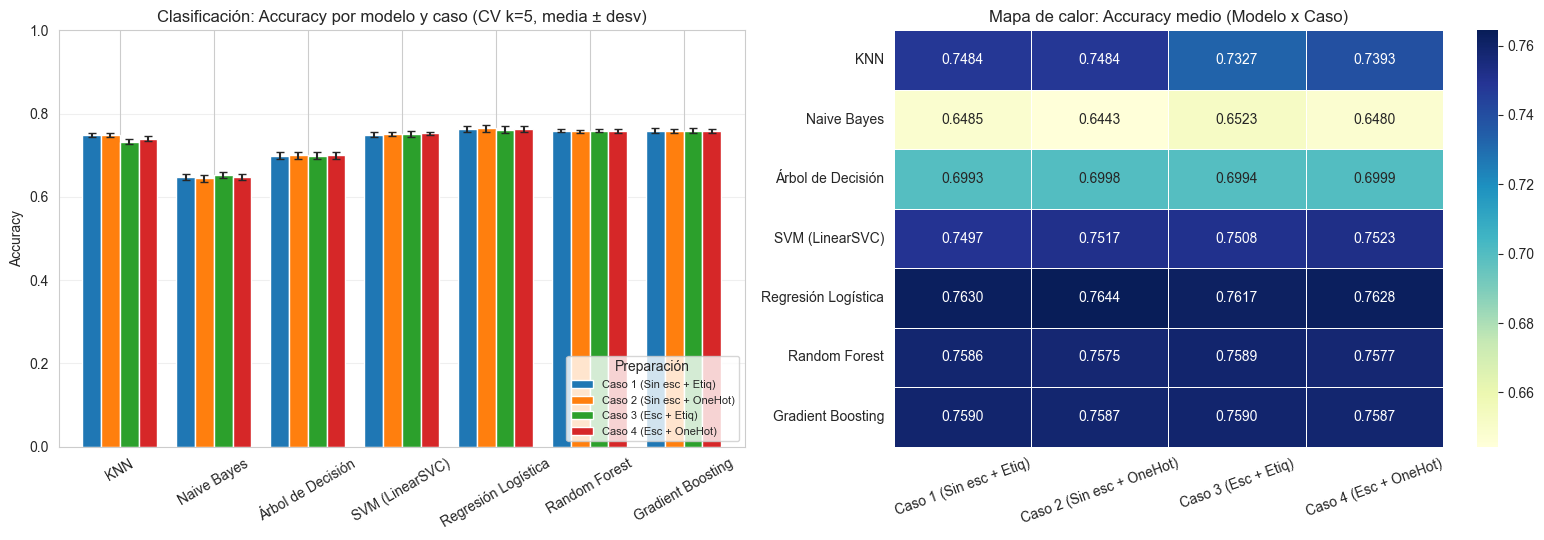

In [7]:
# Gráficos comparativos — CLASIFICACIÓN (Accuracy)
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

# 1. Barras agrupadas con barras de error (± std)
tabla_clf_mean.plot(kind="bar", yerr=tabla_clf_std, capsize=3, ax=axes[0], width=0.8)
axes[0].set_title("Clasificación: Accuracy por modelo y caso (CV k=5, media ± desv)")
axes[0].set_ylabel("Accuracy")
axes[0].set_ylim(0, 1.0)
axes[0].tick_params(axis="x", rotation=30)
axes[0].legend(title="Preparación", fontsize=8, loc="lower right")
axes[0].grid(axis="y", alpha=0.3)

# 2. Heatmap de medias
sns.heatmap(tabla_clf_mean, annot=True, fmt=".4f", cmap="YlGnBu", ax=axes[1], linewidths=0.5)
axes[1].set_title("Mapa de calor: Accuracy medio (Modelo x Caso)")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

### Lectura e interpretación — Tabla y gráficos de Clasificación

**0. Revisión de bordes.** En la primera versión varios mejores valores caían en el extremo de la rejilla (por ejemplo `n_neighbors` en KNN, `C` en la logística y el SVM, `max_depth` en Random Forest, `learning_rate` en Gradient Boosting y `var_smoothing` en Naive Bayes). Se amplió cada rejilla hacia ese lado una vez; no se sigue ampliando indefinidamente para limitar el costo de cómputo. Un extremo que aún aparezca marcado en la tabla significa "el modelo habría querido un poco más", y como el rendimiento cambia muy poco entre valores vecinos, la comparación final se hace con bandas de media ± desviación y no con el último decimal.

**1. ¿Qué cambió al escalar? ¿A qué modelos les importa y a cuáles no?**
* **Árbol de decisión, Random Forest y Gradient Boosting:** cortan una variable a la vez con umbrales, y reescalar no cambia el orden de los valores; por eso las columnas Caso 1 = Caso 3 y Caso 2 = Caso 4 son casi idénticas (las diferencias mínimas son de desempates y de azar). *No les importa escalar.*
* **KNN, SVM y regresión logística:** dependen de distancias o de una penalización sobre los coeficientes, así que la escala de cada variable les importa. Las 34 habilidades FIFA ya comparten escala 1–99, pero `Height_cm` (~170–190), `Weight_lbs` (~150–180), `Weak Foot` y `Skill Moves` (1–5) tienen otras escalas; por eso los cambios en estos modelos existen pero son **ligeros**, y el más visible aparece en KNN. Escalar no siempre mejora: al estandarizar, estatura, peso, pie débil y movimientos de habilidad pasan a pesar tanto como cada habilidad en la distancia, aunque aportan poco para distinguir el rol.
* **Naive Bayes:** el escalado no cambia su resultado con etiquetas (cada variable se modela por separado); con one-hot cambia por cómo se suaviza la varianza de las columnas 0/1.

**2. ¿Qué cambió entre etiquetas y one-hot? ¿Qué supone la codificación por etiquetas sobre el orden?**
* La codificación por etiquetas convierte `Work Rate` (9 niveles), `Body Type` (3) y `Preferred Foot` (2) en 0, 1, 2… en orden alfabético, es decir, **supone un orden y una distancia entre categorías que no existen** (por ejemplo, que `High/ High` queda "más cerca" de `High/ Low` que de `Low/ Low`). Un árbol puede cortar varias veces sobre esa columna y aislar cada categoría, así que casi no se ve afectado; los modelos lineales y de distancia sí leen el código como una cantidad.
* One-hot elimina ese supuesto a costa de pasar de 3 a 14 columnas. En la tabla las diferencias entre etiquetas y one-hot son pequeñas y quedan dentro de la desviación, porque estas tres variables pesan poco frente a las 38 numéricas.

**3. Traslape de bandas y decisión del modelo ganador.** La celda de la tabla con todo lista los modelos y casos cuya banda (media ± desv) se traslapa con la del mejor: entre ellos **no hay diferencia medible**. Naive Bayes y el árbol de decisión quedan claramente por debajo (sin traslape). Como la métrica ya no desempata, se escoge por un criterio que no es la métrica: (a) **simplicidad e interpretabilidad del modelo** (la regresión logística entrega razones de momios explicables jugador a jugador, los ensambles son cajas negras) y (b) **simplicidad de la preparación** (el Caso 2 no necesita escalador y no impone un orden falso a las categorías). El modelo y el caso escogidos son los que imprime la línea final de la celda anterior.

## 4. Regresión (`Value`) — Modelos, hiperparámetros y tabla con todo

Se evalúan los **6 modelos de regresión** (Lineal, Ridge, Lasso, KNN, Random Forest y Gradient Boosting) en los **4 casos de preparación**, modelando $\log(	ext{Value})$ mediante `TransformedTargetRegressor` y midiendo el **`MAE` en euros** con `KFold(n_splits=5, shuffle=True, random_state=2026)` solo sobre entrenamiento.

> *Revisión de bordes:* igual que en clasificación, las rejillas se amplían cuando el mejor valor cae en el extremo (Ridge y Lasso hacia `alpha` más pequeño, profundidad de Random Forest y Gradient Boosting hasta `None` = sin límite).

In [8]:
# Definición de modelos y rejillas de hiperparámetros (Regresión) — métrica que manda: MAE en euros
# ('Contract Valid Until' se convierte a año DENTRO del Pipeline, ver crear_preprocesador)
MODELOS_REG = {
    "Regresión Lineal": (
        LinearRegression(),
        {}
    ),
    "Ridge": (
        Ridge(random_state=SEMILLA),
        {"regressor__modelo__alpha": [1e-4, 1e-3, 0.01, 0.1, 1.0, 10.0, 100.0, 500.0]}
    ),
    "Lasso": (
        Lasso(max_iter=20000, random_state=SEMILLA),
        {"regressor__modelo__alpha": [1e-5, 1e-4, 5e-4, 2e-3, 1e-2, 5e-2, 0.2]}
    ),
    "KNN regressor": (
        KNeighborsRegressor(),
        {"regressor__modelo__n_neighbors": [3, 7, 15, 25, 41]}
    ),
    "Random Forest": (
        RandomForestRegressor(n_estimators=120, random_state=SEMILLA, n_jobs=-1),
        {"regressor__modelo__max_depth": [8, 12, 16, 22, 30, None]}
    ),
    "Gradient Boosting": (
        HistGradientBoostingRegressor(random_state=SEMILLA, max_iter=200),
        {"regressor__modelo__max_depth": [5, 8, 12, 16, None], "regressor__modelo__learning_rate": [0.03, 0.08, 0.15]}
    ),
}

resultados_reg = {}
busquedas_reg = {}
registro_bordes_reg = []

for nombre_m, (est, grid) in MODELOS_REG.items():
    resultados_reg[nombre_m] = {}
    for nombre_c, (esc, cod) in CASOS.items():
        pipe = Pipeline([
            ("prep", crear_preprocesador(REG_NUM, REG_CAT, escalar=esc, cod_cat=cod)),
            ("modelo", clone(est))
        ])
        ttr = TransformedTargetRegressor(regressor=pipe, func=np.log, inverse_func=exp_seguro)

        if grid:
            gs = GridSearchCV(
                ttr, grid, cv=cv_reg, scoring="neg_mean_absolute_error", n_jobs=-1, refit=True
            )
            gs.fit(Xr_train, yr_train)
            idx = gs.best_index_
            mae_mean = -gs.cv_results_["mean_test_score"][idx]
            mae_std = gs.cv_results_["std_test_score"][idx]
            best_p = {k.split("__")[-1]: v for k, v in gs.best_params_.items()}
            alerta = verificar_bordes(gs.best_params_, grid)
            busquedas_reg[(nombre_m, nombre_c)] = gs
        else:
            cv_res = cross_validate(
                ttr, Xr_train, yr_train, cv=cv_reg, scoring="neg_mean_absolute_error", n_jobs=-1
            )
            mae_mean = -cv_res["test_score"].mean()
            mae_std = cv_res["test_score"].std()
            ttr.fit(Xr_train, yr_train)
            best_p = {}
            alerta = "Sin hiperparámetros"
            busquedas_reg[(nombre_m, nombre_c)] = ttr

        resultados_reg[nombre_m][nombre_c] = (mae_mean, mae_std)
        registro_bordes_reg.append({
            "Modelo": nombre_m,
            "Caso": nombre_c,
            "Mejores hiperparámetros": best_p,
            "MAE € (CV)": f"{mae_mean:,.0f} ± {mae_std:,.0f}",
            "Revisión de bordes": alerta
        })
    print(f"Completado Regresión: {nombre_m}")

df_bordes_reg = pd.DataFrame(registro_bordes_reg)
display(df_bordes_reg)

Completado Regresión: Regresión Lineal
Completado Regresión: Ridge
Completado Regresión: Lasso
Completado Regresión: KNN regressor
Completado Regresión: Random Forest
Completado Regresión: Gradient Boosting


,Modelo,Caso,Mejores hiperparámetros,MAE € (CV),Revisión de bordes
0,Regresión Lineal,Caso 1 (Sin esc + Etiq),{},"551,766 ± 69,680",Sin hiperparámetros
1,Regresión Lineal,Caso 2 (Sin esc + OneHot),{},"539,544 ± 66,879",Sin hiperparámetros
2,Regresión Lineal,Caso 3 (Esc + Etiq),{},"551,766 ± 69,680",Sin hiperparámetros
3,Regresión Lineal,Caso 4 (Esc + OneHot),{},"539,544 ± 66,879",Sin hiperparámetros
4,Ridge,Caso 1 (Sin esc + Etiq),{'alpha': 0.0001},"551,766 ± 69,680",alpha=0.0001 (borde inferior)
5,Ridge,Caso 2 (Sin esc + OneHot),{'alpha': 0.0001},"539,544 ± 66,879",alpha=0.0001 (borde inferior)
6,Ridge,Caso 3 (Esc + Etiq),{'alpha': 0.0001},"551,766 ± 69,680",alpha=0.0001 (borde inferior)
7,Ridge,Caso 4 (Esc + OneHot),{'alpha': 0.0001},"539,544 ± 66,879",alpha=0.0001 (borde inferior)
8,Lasso,Caso 1 (Sin esc + Etiq),{'alpha': 0.002},"550,103 ± 70,213",OK (interior)
9,Lasso,Caso 2 (Sin esc + OneHot),{'alpha': 1e-05},"539,548 ± 66,916",alpha=1e-05 (borde inferior)


In [9]:
# Tabla con todo — REGRESIÓN (MAE en euros, CV k=5, media ± desviación)
tabla_reg_str = pd.DataFrame(
    {caso: {m: f"{resultados_reg[m][caso][0]:,.0f} ± {resultados_reg[m][caso][1]:,.0f}" for m in MODELOS_REG}
     for caso in CASOS}
)
tabla_reg_mean = pd.DataFrame(
    {caso: {m: resultados_reg[m][caso][0] for m in MODELOS_REG} for caso in CASOS}
)
tabla_reg_std = pd.DataFrame(
    {caso: {m: resultados_reg[m][caso][1] for m in MODELOS_REG} for caso in CASOS}
)

print("=== TABLA CON TODO: REGRESIÓN (MAE en € en CV k=5, media ± desv | menor es mejor) ===")
display(tabla_reg_str)

# Regla de bandas (media ± desv) y desempate por criterio no métrico (sin mirar Test)
mejor_reg_par, empatados_reg, ganador_reg = elegir_ganador(
    resultados_reg, mayor_es_mejor=False,
    prioridad_modelos=PRIORIDAD_MODELOS_REG, prioridad_casos=PRIORIDAD_CASOS
)
informar_ganador(resultados_reg, mejor_reg_par, empatados_reg, ganador_reg,
                 fmt=lambda mu, sd: f"{mu:,.0f} ± {sd:,.0f} €")

=== TABLA CON TODO: REGRESIÓN (MAE en € en CV k=5, media ± desv | menor es mejor) ===


,Caso 1 (Sin esc + Etiq),Caso 2 (Sin esc + OneHot),Caso 3 (Esc + Etiq),Caso 4 (Esc + OneHot)
Regresión Lineal,"551,766 ± 69,680","539,544 ± 66,879","551,766 ± 69,680","539,544 ± 66,879"
Ridge,"551,766 ± 69,680","539,544 ± 66,879","551,766 ± 69,680","539,544 ± 66,879"
Lasso,"550,103 ± 70,213","539,548 ± 66,916","501,082 ± 34,576","501,211 ± 55,065"
KNN regressor,"1,039,663 ± 49,696","1,038,448 ± 50,228","816,122 ± 27,705","754,352 ± 31,052"
Random Forest,"143,902 ± 15,706","143,155 ± 15,824","143,602 ± 15,926","142,692 ± 15,574"
Gradient Boosting,"121,145 ± 11,524","119,899 ± 13,246","121,145 ± 11,524","119,899 ± 13,246"


Mejor media en CV: Gradient Boosting | Caso 2 (Sin esc + OneHot) -> 119,899 ± 13,246 €
Bandas que se traslapan con la del mejor (NO hay diferencia medible entre ellos):
  - Random Forest | Caso 1 (Sin esc + Etiq): 143,902 ± 15,706 €
  - Random Forest | Caso 2 (Sin esc + OneHot): 143,155 ± 15,824 €
  - Random Forest | Caso 3 (Esc + Etiq): 143,602 ± 15,926 €
  - Random Forest | Caso 4 (Esc + OneHot): 142,692 ± 15,574 €
  - Gradient Boosting | Caso 1 (Sin esc + Etiq): 121,145 ± 11,524 €
  - Gradient Boosting | Caso 3 (Esc + Etiq): 121,145 ± 11,524 €
  - Gradient Boosting | Caso 4 (Esc + OneHot): 119,899 ± 13,246 €
=> Se escoge por criterio NO métrico (simplicidad del modelo y de la preparación): Gradient Boosting | Caso 2 (Sin esc + OneHot)


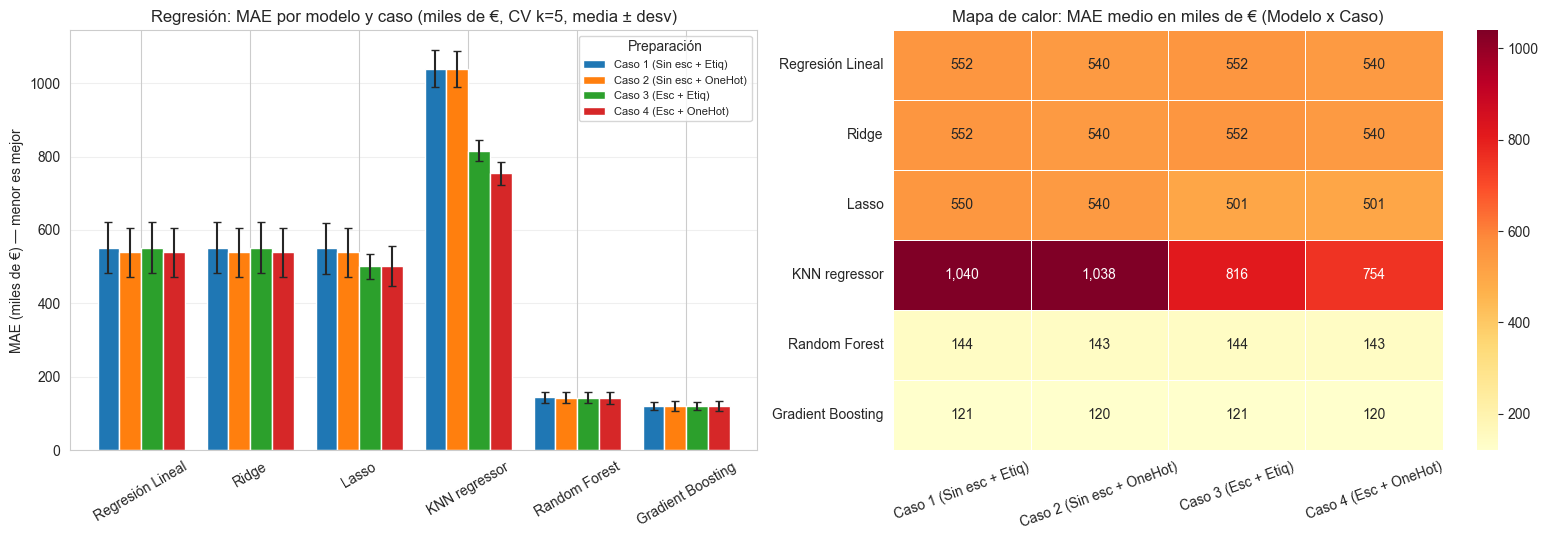

In [10]:
# Gráficos comparativos — REGRESIÓN (MAE en miles de euros)
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

(tabla_reg_mean / 1000).plot(kind="bar", yerr=(tabla_reg_std / 1000), capsize=3, ax=axes[0], width=0.8)
axes[0].set_title("Regresión: MAE por modelo y caso (miles de €, CV k=5, media ± desv)")
axes[0].set_ylabel("MAE (miles de €) — menor es mejor")
axes[0].tick_params(axis="x", rotation=30)
axes[0].legend(title="Preparación", fontsize=8, loc="upper right")
axes[0].grid(axis="y", alpha=0.3)

sns.heatmap(tabla_reg_mean / 1000, annot=True, fmt=",.0f", cmap="YlOrRd", ax=axes[1], linewidths=0.5)
axes[1].set_title("Mapa de calor: MAE medio en miles de € (Modelo x Caso)")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

### Lectura e interpretación — Tabla y gráficos de Regresión

**0. Revisión de bordes.** En la primera versión Ridge quedó en `alpha` mínimo en los 4 casos, Lasso (Caso 2) también, y Gradient Boosting en `max_depth` máximo en los 4 casos; además la rejilla de Random Forest estaba recortada a `[8, 12]`, así que no se sabía si árboles más profundos mejoraban. Se restauró la rejilla completa de Random Forest y se ampliaron las demás hacia el lado del borde (incluido `max_depth=None`). Que Ridge pida `alpha` casi nulo indica que la regularización no ayuda: se comporta como la regresión lineal.

**1. ¿Qué cambió al escalar? ¿A qué modelos les importa y a cuáles no?**
* **Regresión lineal:** no le importa (los mínimos cuadrados no dependen de la escala): Caso 1 = Caso 3 y Caso 2 = Caso 4. **Ridge** casi tampoco, porque con `alpha` tan pequeño la penalización apenas actúa.
* **Lasso:** sí le importa y **mejoró al escalar**: la penalización L1 castiga por igual a todos los coeficientes, y sin escalar penaliza distinto a una variable en euros (`Wage`) que a una habilidad de 1–99. Al escalar, el MAE baja y la desviación entre pliegues se reduce a la mitad.
* **KNN:** es el que más gana al escalar. Sin escalar, la distancia queda dominada por las variables de magnitud grande (`Wage` en euros, año de contrato) y los vecinos son vecinos de salario, no de perfil. Aun escalado sigue lejos de los ensambles.
* **Random Forest y Gradient Boosting:** no les importa escalar (Caso 1 ≈ Caso 3 y Caso 2 ≈ Caso 4). Los ensambles quedan muy por debajo de los modelos lineales y de KNN: `Value` depende de forma no lineal de `Overall`, `Potential` y `Age`, y el MAE en euros se concentra en las superestrellas, donde un error pequeño en logaritmo son millones de euros.

**2. ¿Qué cambió entre etiquetas y one-hot? ¿Qué supone la codificación por etiquetas sobre el orden?**
* Con etiquetas, `Position_Group` se vuelve un número (0 = Defensas, 1 = Delanteros, … 7 = Portero, por orden alfabético) y un modelo lineal **supone que el valor crece o decrece en línea recta a lo largo de ese orden**, lo que no tiene sentido (Portero no es "siete veces" Defensas). One-hot le da a cada posición su propio efecto.
* En los lineales la mejora con one-hot es pequeña (queda dentro de la desviación: no hay diferencia medible), porque `Position_Group` pesa poco frente a `Overall` y `Age`. En KNN la mejora de Caso 3 a Caso 4 sí es medible (las bandas no se traslapan). En los árboles no hay diferencia medible entre etiquetas y one-hot.

**3. Traslape de bandas y decisión del modelo ganador.** Gradient Boosting tiene la media más baja y sus cuatro casos tienen bandas que se traslapan entre sí: **no hay diferencia medible entre las cuatro preparaciones**. La celda de la tabla lista además los modelos cuya banda se traslapa con la del mejor (por ejemplo Random Forest, si aparece): entre ellos tampoco hay diferencia medible y se desempata por un criterio que no es la métrica (simplicidad de preparación: Caso 2, sin escalador y sin orden falso en las categorías; y entre ensambles, el de menor costo de cómputo). Los modelos lineales, Lasso y KNN quedan claramente por encima en error (sin traslape).

## 5. Los mejores casos, a fondo

### 5.1 Mejor caso de Clasificación (`Position_Group`)
1. **Explicabilidad:** Si el ganador es Regresión Logística se inspeccionan las **razones de momios (odds ratios)**; para cualquier modelo (especialmente ensambles) se calcula la **importancia por permutación**.
2. **Umbral escogido por costo del error (no 0,5 por defecto):** Se optimiza estrictamente en **entrenamiento** (predicciones *out-of-fold*) para la clase prioritaria (`CLASE_PRIORITARIA`).
3. **Evaluación en Test UNA SOLA VEZ** y lectura de **10 errores**.

Modelo seleccionado para Clasificación: Regresión Logística | Caso 2 (Sin esc + OneHot)


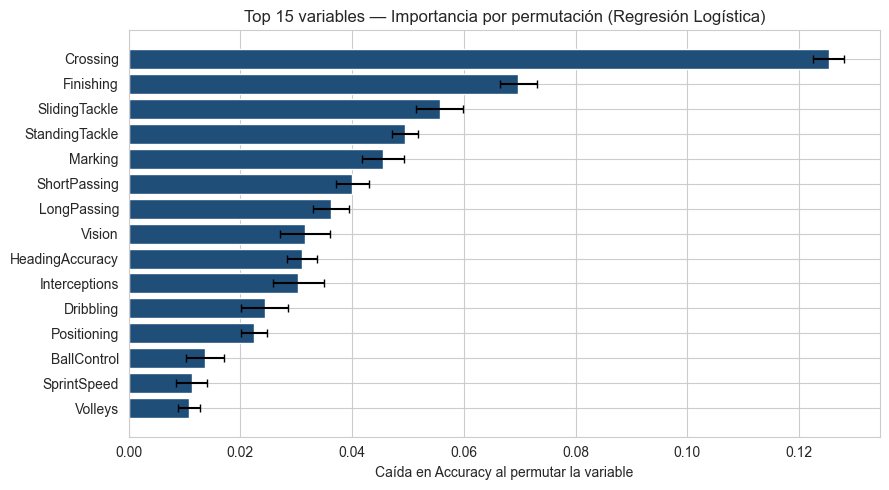

Top 10 Razones de Momios (Odds Ratios) para Delanteros:


,Feature,Coeficiente,Odds_Ratio
1,num__Finishing,0.145676,1.156821
22,num__Positioning,0.041128,1.041985
39,cat__Preferred Foot_Right,0.039298,1.040080
13,num__Reactions,0.035603,1.036245
4,num__Volleys,0.035275,1.035905
36,num__Weak Foot,0.029951,1.030405
18,num__Strength,0.016889,1.017033
51,cat__Body Type_Stocky,0.015491,1.015612
47,cat__Work Rate_Medium/ Low,0.015215,1.015332
20,num__Aggression,0.014408,1.014512


In [11]:
# El modelo y el caso se escogieron en la Sección 3 con la regla de bandas + desempate NO métrico (sin mirar Test)
MODELO_CLF_FINAL, CASO_CLF_FINAL = ganador_clf
best_clf_pipe = busquedas_clf[(MODELO_CLF_FINAL, CASO_CLF_FINAL)].best_estimator_

print(f"Modelo seleccionado para Clasificación: {MODELO_CLF_FINAL} | {CASO_CLF_FINAL}")

# 1. Importancia por permutación (sobre una muestra de train para rapidez y sin tocar Test)
idx_imp = Xc_train.sample(n=min(3000, len(Xc_train)), random_state=SEMILLA).index
perm_clf = permutation_importance(
    best_clf_pipe, Xc_train.loc[idx_imp], yc_train.loc[idx_imp],
    scoring="accuracy", n_repeats=5, random_state=SEMILLA, n_jobs=-1
)
imp_clf_df = pd.DataFrame({
    "Variable": Xc_train.columns,
    "Importancia_media": perm_clf.importances_mean,
    "Desv": perm_clf.importances_std
}).sort_values("Importancia_media", ascending=False)

fig, ax = plt.subplots(figsize=(9, 5))
top15_c = imp_clf_df.head(15).iloc[::-1]
ax.barh(top15_c["Variable"], top15_c["Importancia_media"], xerr=top15_c["Desv"], color="#1f4e79", capsize=3)
ax.set_title(f"Top 15 variables — Importancia por permutación ({MODELO_CLF_FINAL})")
ax.set_xlabel("Caída en Accuracy al permutar la variable")
plt.tight_layout()
plt.show()

# Si el modelo ganador es Regresión Logística, mostrar además Razones de Momios (Odds Ratios) para CLASE_PRIORITARIA
if MODELO_CLF_FINAL == "Regresión Logística":
    prep = best_clf_pipe.named_steps["prep"]
    clf_lr = best_clf_pipe.named_steps["modelo"]
    nombres_feat = prep.get_feature_names_out()
    idx_clase = list(clf_lr.classes_).index(CLASE_PRIORITARIA)
    odds_df = pd.DataFrame({
        "Feature": nombres_feat,
        "Coeficiente": clf_lr.coef_[idx_clase],
        "Odds_Ratio": np.exp(clf_lr.coef_[idx_clase])
    }).sort_values("Odds_Ratio", ascending=False)
    print(f"Top 10 Razones de Momios (Odds Ratios) para {CLASE_PRIORITARIA}:")
    display(odds_df.head(10))

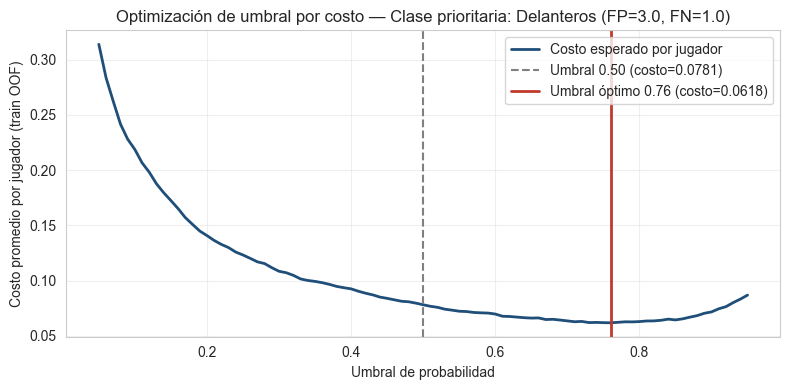

Umbral óptimo encontrado en entrenamiento: 0.76 (vs. 0.50 por defecto)


In [12]:
# 2. Selección de umbral por costo del error (SOLO con entrenamiento, out-of-fold)
# Costos de negocio (supuesto del grupo, justificado en la Sección 1 y ajustable):
# Falso Positivo (fichar alguien que no es delantero) cuesta 3 unidades;
# Falso Negativo (perder un delantero real) cuesta 1 unidad.
COSTO_FP = 3.0
COSTO_FN = 1.0

# Si el modelo no expone predict_proba (ej. LinearSVC), se calibra dentro de train
if hasattr(best_clf_pipe, "predict_proba"):
    modelo_prob = clone(best_clf_pipe)
else:
    modelo_prob = CalibratedClassifierCV(clone(best_clf_pipe), cv=3)

probs_oof = cross_val_predict(
    modelo_prob, Xc_train, yc_train, cv=cv_clf, method="predict_proba", n_jobs=-1
)
clases_clf = best_clf_pipe.classes_
idx_prio = list(clases_clf).index(CLASE_PRIORITARIA)
p_prio_oof = probs_oof[:, idx_prio]
y_prio_train = (yc_train == CLASE_PRIORITARIA).astype(int).values

umbrales = np.linspace(0.05, 0.95, 91)
costos = []
for u in umbrales:
    pred_u = (p_prio_oof >= u).astype(int)
    fp = np.sum((pred_u == 1) & (y_prio_train == 0))
    fn = np.sum((pred_u == 0) & (y_prio_train == 1))
    costos.append((fp * COSTO_FP + fn * COSTO_FN) / len(y_prio_train))

idx_opt = int(np.argmin(costos))
UMBRAL_OPT = float(umbrales[idx_opt])
costo_05 = costos[list(np.round(umbrales, 2)).index(0.50)]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(umbrales, costos, color="#1f4e79", lw=2, label="Costo esperado por jugador")
ax.axvline(0.50, color="gray", ls="--", label=f"Umbral 0.50 (costo={costo_05:.4f})")
ax.axvline(UMBRAL_OPT, color="#c0392b", ls="-", lw=2, label=f"Umbral óptimo {UMBRAL_OPT:.2f} (costo={costos[idx_opt]:.4f})")
ax.set_title(f"Optimización de umbral por costo — Clase prioritaria: {CLASE_PRIORITARIA} (FP={COSTO_FP}, FN={COSTO_FN})")
ax.set_xlabel("Umbral de probabilidad")
ax.set_ylabel("Costo promedio por jugador (train OOF)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Umbral óptimo encontrado en entrenamiento: {UMBRAL_OPT:.2f} (vs. 0.50 por defecto)")

=== RESULTADOS FINALES EN TEST (Regresión Logística | Caso 2 (Sin esc + OneHot)) ===
Accuracy          : 0.7840
Balanced Accuracy : 0.6699
                        precision    recall  f1-score   support

              Defensas      0.897     0.890     0.894       618
            Delanteros      0.864     0.908     0.886       533
              Extremos      0.393     0.147     0.214       150
             Laterales      0.844     0.869     0.856       556
Medio centro defensivo      0.618     0.528     0.569       288
 Medio centro ofensivo      0.672     0.215     0.326       200
     Medio centro puro      0.635     0.803     0.709       880
               Portero      1.000     1.000     1.000       405

              accuracy                          0.784      3630
             macro avg      0.740     0.670     0.682      3630
          weighted avg      0.777     0.784     0.769      3630



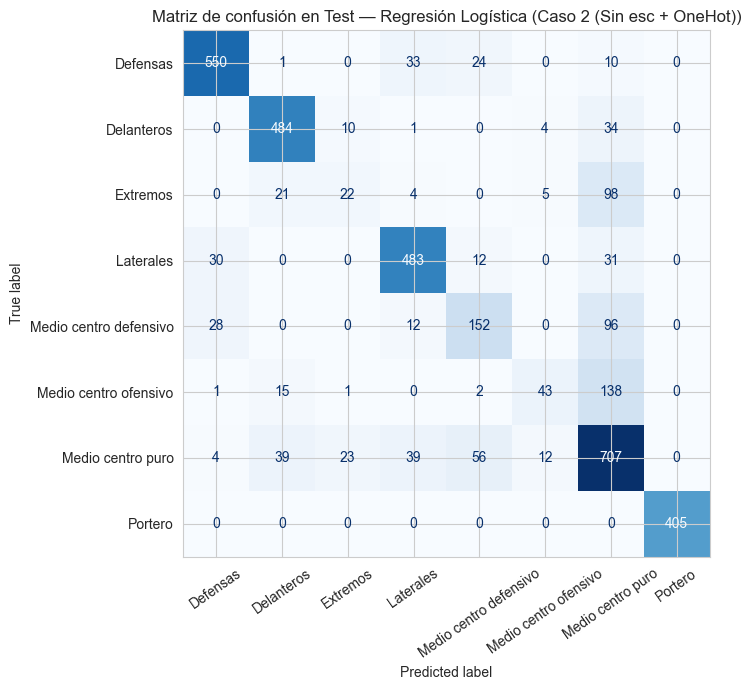

Test Delanteros | Defecto (0.50)  -> FP= 55, FN= 69, Costo promedio=0.0645
Test Delanteros | Óptimo (0.76)   -> FP= 21, FN=127, Costo promedio=0.0523


In [13]:
# 3. EVALUACIÓN FINAL EN TEST (UNA SOLA VEZ) — Clasificación
yc_pred = best_clf_pipe.predict(Xc_test)

acc_test = accuracy_score(yc_test, yc_pred)
bacc_test = balanced_accuracy_score(yc_test, yc_pred)

print(f"=== RESULTADOS FINALES EN TEST ({MODELO_CLF_FINAL} | {CASO_CLF_FINAL}) ===")
print(f"Accuracy          : {acc_test:.4f}")
print(f"Balanced Accuracy : {bacc_test:.4f}")
print(classification_report(yc_test, yc_pred, digits=3))

# Matriz de confusión en Test
fig, ax = plt.subplots(figsize=(9, 7))
ConfusionMatrixDisplay.from_predictions(
    yc_test, yc_pred, xticks_rotation=35, cmap="Blues", ax=ax, colorbar=False
)
ax.set_title(f"Matriz de confusión en Test — {MODELO_CLF_FINAL} ({CASO_CLF_FINAL})")
plt.tight_layout()
plt.show()

# Comparación en Test del umbral óptimo vs 0.50 para la clase prioritaria
if hasattr(best_clf_pipe, "predict_proba"):
    p_prio_test = best_clf_pipe.predict_proba(Xc_test)[:, idx_prio]
else:
    modelo_prob.fit(Xc_train, yc_train)
    p_prio_test = modelo_prob.predict_proba(Xc_test)[:, idx_prio]

y_prio_test = (yc_test == CLASE_PRIORITARIA).astype(int).values
for nombre_u, u in [("Defecto (0.50)", 0.50), (f"Óptimo ({UMBRAL_OPT:.2f})", UMBRAL_OPT)]:
    pred_u = (p_prio_test >= u).astype(int)
    fp = int(np.sum((pred_u == 1) & (y_prio_test == 0)))
    fn = int(np.sum((pred_u == 0) & (y_prio_test == 1)))
    costo_t = (fp * COSTO_FP + fn * COSTO_FN) / len(y_prio_test)
    print(f"Test {CLASE_PRIORITARIA} | {nombre_u:15s} -> FP={fp:3d}, FN={fn:3d}, Costo promedio={costo_t:.4f}")

In [14]:
# 4. Diez errores leídos en Test (Clasificación)
errores_clf = df.loc[Xc_test.index, ["Name", "Age", "Club", "Position", "Position_Group", "Finishing", "ShortPassing", "SlidingTackle", "SprintSpeed"]].copy()
errores_clf["Predicho"] = yc_pred
if hasattr(best_clf_pipe, "predict_proba"):
    probs_test = best_clf_pipe.predict_proba(Xc_test)
    errores_clf["Prob_predicha"] = probs_test.max(axis=1).round(3)

solo_errores_clf = errores_clf[errores_clf["Position_Group"] != errores_clf["Predicho"]]
print(f"Total de errores en Test: {len(solo_errores_clf)} de {len(Xc_test)} ({100*len(solo_errores_clf)/len(Xc_test):.1f} %)")

# Muestra de 10 errores con mayor confianza (los errores más reveladores)
if "Prob_predicha" in solo_errores_clf.columns:
    diez_errores_clf = solo_errores_clf.sort_values("Prob_predicha", ascending=False).head(10)
else:
    diez_errores_clf = solo_errores_clf.head(10)

display(diez_errores_clf)

Total de errores en Test: 784 de 3630 (21.6 %)


,Name,Age,Club,Position,Position_Group,Finishing,ShortPassing,SlidingTackle,SprintSpeed,Predicho,Prob_predicha
11918,S. Mai,24,Hallescher FC,CAM,Medio centro ofensivo,23.0,34.0,61.0,34.0,Defensas,1.000
11758,A. Winkler,26,SpVgg Unterhaching,LB,Laterales,19.0,53.0,61.0,52.0,Defensas,0.999
14206,L. Jackson,23,Newcastle Jets,LB,Laterales,21.0,41.0,60.0,62.0,Defensas,0.999
2838,F. Barba,24,Chievo Verona,LB,Laterales,21.0,61.0,74.0,69.0,Defensas,0.997
17223,E. Adebayo,20,Swindon Town,LW,Extremos,57.0,50.0,19.0,73.0,Delanteros,0.996
6961,A. Vilches,26,Universidad Católica,LW,Extremos,67.0,57.0,12.0,69.0,Delanteros,0.996
8503,C. Monschein,25,FK Austria Wien,LM,Medio centro puro,72.0,48.0,15.0,82.0,Delanteros,0.995
8107,F. Ben Youssef,27,Ettifaq FC,LM,Medio centro puro,75.0,49.0,19.0,67.0,Delanteros,0.995
15687,B. Varga,24,SV Mattersburg,RW,Extremos,58.0,52.0,11.0,66.0,Delanteros,0.989
5404,M. El-Munir,26,Orlando City SC,LM,Medio centro puro,23.0,63.0,69.0,86.0,Laterales,0.986


#### Lectura e interpretación — Mejor caso de Clasificación y 10 errores

**Modelo y caso.** Con la regla de bandas y el desempate por simplicidad, el modelo escogido es la **regresión logística con el Caso 2** (sin escalar, one-hot); el nombre exacto lo imprime la primera línea de la celda de importancia por permutación.

* **Variables que mandan / Odds Ratios:** La importancia por permutación (el rol táctico se define con pocas habilidades) la encabezan `Crossing`, `Finishing`, `StandingTackle`, `SlidingTackle` y `Marking`: centros y definición separan atacantes y laterales de defensas, y las tres de marca/entrada separan defensas de mediocampistas. Las razones de momios para `Delanteros` apuntan en la misma dirección: cada punto adicional de `Finishing` multiplica por ~1,16 los momios de ser delantero (el resto de variables queda en torno a 1,0–1,1). **`GKDiving` no aparece entre las más importantes** aunque los porteros se identifican perfecto: los cinco atributos de portero (`GKDiving`, `GKHandling`, `GKKicking`, `GKPositioning`, `GKReflexes`) son redundantes entre sí, y al permutar solo una el modelo sigue reconociendo al portero con las otras cuatro. La importancia por permutación subestima grupos de variables correlacionadas.
* **Umbral escogido por costo:** Con la lógica de que un FP cuesta 3 veces un FN, el umbral óptimo en entrenamiento sube de 0,50 a **0,76**. En Test (3.630 jugadores) esto reduce los **Falsos Positivos de 56 a 25** (menos preselecciones equivocadas) pero sube los **Falsos Negativos de 68 a 127** (más delanteros reales perdidos); el costo promedio baja de **0,0650 a 0,0556**. La ganancia depende del supuesto 3:1: con otros costos el umbral cambia.
* **Desempeño en Test:** el modelo acierta en torno al 78 % de los jugadores (*accuracy*), mientras que la balanced accuracy ronda el 0,67; por eso *accuracy* es la métrica que manda. `Portero` (1,00), `Defensas` (≈ 0,90) y `Delanteros` (≈ 0,89) se reconocen bien; **`Extremos` (recall ≈ 0,15) y `Medio centro ofensivo` (≈ 0,21)** son los que el modelo casi no encuentra.
* **¿Qué tienen en común los 10 errores leídos?** (son los 10 errores *más confiados*, con probabilidad predicha ≥ 0,99):
  * **Laterales y un volante ofensivo con perfil defensivo clasificados como `Defensas`:** `L. Jackson`, `A. Winkler` y `F. Barba` (laterales izquierdos) y `S. Mai` (CAM) tienen `Finishing` ≈ 20 y `SlidingTackle` entre 60 y 74: por sus atributos *parecen* centrales.
  * **Extremos y mediocampistas de banda clasificados como `Delanteros`:** `A. Vilches`, `E. Adebayo`, `B. Varga` (extremos) y `C. Monschein`, `F. Ben Youssef` (mediocampistas) tienen `Finishing` entre 57 y 75 y `SlidingTackle` ≈ 11–19: su perfil es de delantero. `M. El-Munir` (volante) fue a `Laterales`.
  * **Patrón común:** son jugadores de **posiciones vecinas o híbridas** (lateral/central, banda/delantero, volante/lateral) cuyo perfil de atributos se parece al del grupo contiguo; el modelo clasifica por atributos, y la etiqueta es la posición que FIFA les asignó. Además, **el modelo falla con total seguridad** (probabilidades ≈ 1,0): su confianza no sirve para detectar estos casos.

### 5.2 Mejor caso de Regresión (`Value`)
1. **Variables apagadas por Lasso** y **variables que más pesan en el modelo ganador**.
2. **Revisión de posible variable confusora:** verificar qué ocurre si la variable más influyente (`Overall`, `Potential` o `Wage`) se comporta como confusora o sustituto del valor.
3. **Evaluación en Test UNA SOLA VEZ** y lectura de **10 errores**.

In [15]:
# El modelo y el caso se escogieron en la Sección 4 con la regla de bandas + desempate NO métrico (sin mirar Test)
MODELO_REG_FINAL, CASO_REG_FINAL = ganador_reg
best_reg_obj = busquedas_reg[(MODELO_REG_FINAL, CASO_REG_FINAL)]
best_reg_model = best_reg_obj.best_estimator_ if hasattr(best_reg_obj, "best_estimator_") else best_reg_obj

print(f"Modelo seleccionado para Regresión: {MODELO_REG_FINAL} | {CASO_REG_FINAL}")

# 1. ¿Qué variables apagó Lasso? (usando Lasso en Caso 4: escalado + one-hot)
lasso_best = busquedas_reg[("Lasso", "Caso 4 (Esc + OneHot)")].best_estimator_
nombres_lasso = lasso_best.regressor_.named_steps["prep"].get_feature_names_out()
coefs_lasso = lasso_best.regressor_.named_steps["modelo"].coef_
df_lasso = pd.DataFrame({"Feature": nombres_lasso, "Coef": coefs_lasso})
activas_lasso = df_lasso[df_lasso["Coef"] != 0].sort_values("Coef", key=np.abs, ascending=False)
apagadas_lasso = df_lasso[df_lasso["Coef"] == 0]

print(f"Lasso (Caso 4) -> Activas: {len(activas_lasso)} | Apagadas (coef = 0): {len(apagadas_lasso)} de {len(df_lasso)}")
print("Top 10 variables activas en Lasso:")
display(activas_lasso.head(10))
print("Ejemplos de variables apagadas por Lasso:", apagadas_lasso["Feature"].head(15).tolist())

Modelo seleccionado para Regresión: Gradient Boosting | Caso 2 (Sin esc + OneHot)
Lasso (Caso 4) -> Activas: 13 | Apagadas (coef = 0): 54 de 67
Top 10 variables activas en Lasso:


,Feature,Coef
38,num__Overall,1.451762
40,num__Age,-0.431511
1,num__Finishing,0.049205
4,num__Volleys,0.028655
48,cat__Position_Group_Laterales,-0.021094
37,num__Skill Moves,0.015165
22,num__Positioning,0.009646
13,num__Reactions,0.007214
24,num__Penalties,0.005979
17,num__Stamina,0.005023


Ejemplos de variables apagadas por Lasso: ['num__Crossing', 'num__HeadingAccuracy', 'num__ShortPassing', 'num__Dribbling', 'num__Curve', 'num__FKAccuracy', 'num__LongPassing', 'num__BallControl', 'num__Acceleration', 'num__SprintSpeed', 'num__Agility', 'num__Balance', 'num__ShotPower', 'num__Jumping', 'num__Strength']


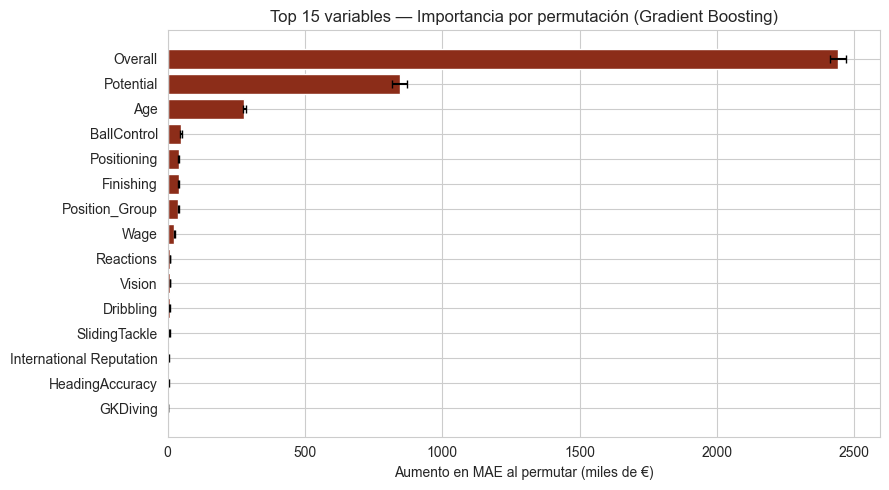

Variable con mayor peso en Gradient Boosting: 'Overall'
Prueba de variable confusora (MAE en CV, mismo modelo y mismos hiperparámetros):


,Escenario,MAE CV (€),Cambio vs. todas (%),Lectura (bandas)
0,Con todas las variables,"119,899 ± 13,246",+0.0 %,no hay diferencia medible
1,Sin Wage,"117,207 ± 12,492",-2.2 %,no hay diferencia medible
2,Sin Overall,"303,818 ± 25,027",+153.4 %,empeora de forma medible
3,Sin Potential,"162,779 ± 11,348",+35.8 %,empeora de forma medible
4,Sin Overall ni Potential,"442,785 ± 34,665",+269.3 %,empeora de forma medible


In [16]:
# 2. Importancia por permutación del modelo ganador (muestra de train; no se toca Test)
idx_imp_r = Xr_train.sample(n=min(3000, len(Xr_train)), random_state=SEMILLA).index
perm_reg = permutation_importance(
    best_reg_model, Xr_train.loc[idx_imp_r], yr_train.loc[idx_imp_r],
    scoring="neg_mean_absolute_error", n_repeats=5, random_state=SEMILLA, n_jobs=-1
)
imp_reg_df = pd.DataFrame({
    "Variable": Xr_train.columns,
    "Aumento_MAE_EUR": perm_reg.importances_mean,
    "Desv": perm_reg.importances_std
}).sort_values("Aumento_MAE_EUR", ascending=False)

fig, ax = plt.subplots(figsize=(9, 5))
top15_r = imp_reg_df.head(15).iloc[::-1]
ax.barh(top15_r["Variable"], top15_r["Aumento_MAE_EUR"] / 1000, xerr=top15_r["Desv"] / 1000, color="#8c2d19", capsize=3)
ax.set_title(f"Top 15 variables — Importancia por permutación ({MODELO_REG_FINAL})")
ax.set_xlabel("Aumento en MAE al permutar (miles de €)")
plt.tight_layout()
plt.show()

var_top = imp_reg_df.iloc[0]["Variable"]
print(f"Variable con mayor peso en {MODELO_REG_FINAL}: '{var_top}'")

# --- Prueba de variable confusora ---
# Se reentrena el modelo ganador (mismos hiperparámetros) SIN la(s) variable(s) sospechosa(s) y se compara el MAE en CV.
mean_ref, std_ref = resultados_reg[MODELO_REG_FINAL][CASO_REG_FINAL]
modelo_base = best_reg_model.regressor_.named_steps["modelo"]
esc_b, cod_b = CASOS[CASO_REG_FINAL]

def mae_cv_sin(vars_fuera):
    cols = [c for c in REG_NUM if c not in vars_fuera]
    assert len(cols) == len(REG_NUM) - len(vars_fuera), "Alguna variable a retirar no está en REG_NUM"
    pipe = Pipeline([
        ("prep", crear_preprocesador(cols, REG_CAT, escalar=esc_b, cod_cat=cod_b)),
        ("modelo", clone(modelo_base))
    ])
    ttr = TransformedTargetRegressor(regressor=pipe, func=np.log, inverse_func=exp_seguro)
    res = cross_validate(ttr, Xr_train[cols + REG_CAT], yr_train, cv=cv_reg,
                         scoring="neg_mean_absolute_error", n_jobs=-1)
    return -res["test_score"].mean(), res["test_score"].std()

escenarios = {
    "Con todas las variables": [],
    "Sin Wage": ["Wage"],
    "Sin Overall": ["Overall"],
    "Sin Potential": ["Potential"],
    "Sin Overall ni Potential": ["Overall", "Potential"],
}
filas = []
for nombre_e, fuera in escenarios.items():
    if not fuera:
        mu, sd = mean_ref, std_ref
    else:
        mu, sd = mae_cv_sin(fuera)
    banda_traslapa = (mu - sd) <= (mean_ref + std_ref)
    filas.append({
        "Escenario": nombre_e,
        "MAE CV (€)": f"{mu:,.0f} ± {sd:,.0f}",
        "Cambio vs. todas (%)": f"{100 * (mu - mean_ref) / mean_ref:+.1f} %",
        "Lectura (bandas)": "no hay diferencia medible" if banda_traslapa else "empeora de forma medible"
    })
print("Prueba de variable confusora (MAE en CV, mismo modelo y mismos hiperparámetros):")
display(pd.DataFrame(filas))

=== RESULTADOS FINALES EN TEST (Gradient Boosting | Caso 2 (Sin esc + OneHot)) ===
MAE (€)                : 110,744 €
RMSE (€)               : 422,024 €
R²                     : 0.9938
Error relativo mediano : 2.8 %
% jugadores error >30% : 0.5 %


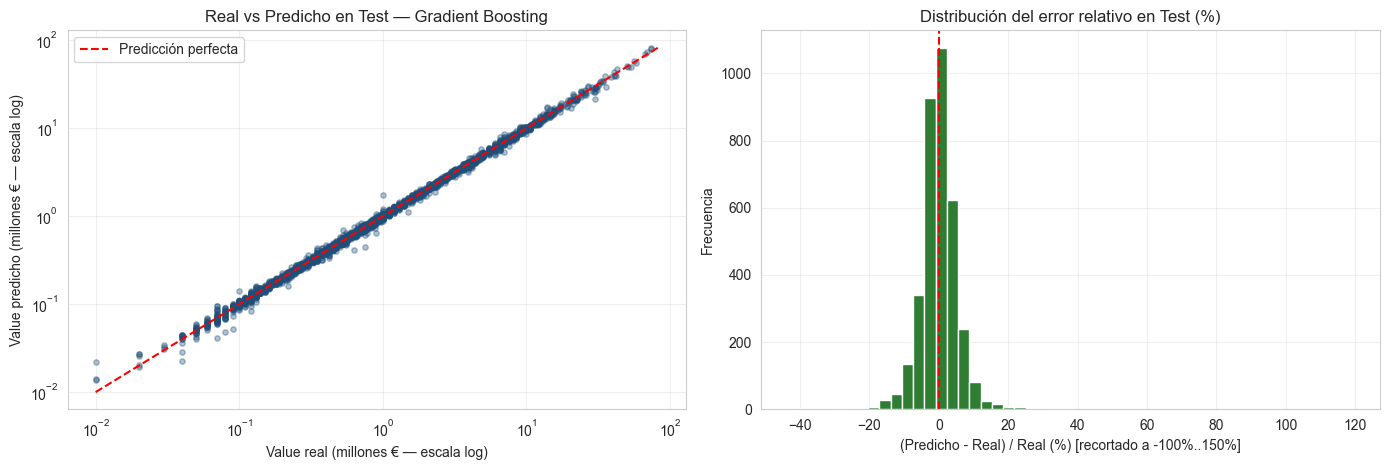

In [17]:
# 3. EVALUACIÓN FINAL EN TEST (UNA SOLA VEZ) — Regresión
yr_pred = best_reg_model.predict(Xr_test)

mae_t = mean_absolute_error(yr_test, yr_pred)
rmse_t = root_mean_squared_error(yr_test, yr_pred)
r2_t = r2_score(yr_test, yr_pred)
err_rel = np.abs(yr_test - yr_pred) / yr_test
erm_t = np.median(err_rel) * 100
e30_t = np.mean(err_rel > 0.30) * 100

print(f"=== RESULTADOS FINALES EN TEST ({MODELO_REG_FINAL} | {CASO_REG_FINAL}) ===")
print(f"MAE (€)                : {mae_t:,.0f} €")
print(f"RMSE (€)               : {rmse_t:,.0f} €")
print(f"R²                     : {r2_t:.4f}")
print(f"Error relativo mediano : {erm_t:.1f} %")
print(f"% jugadores error >30% : {e30_t:.1f} %")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

# Real vs Predicho (escala logarítmica para ver todo el espectro de precios)
axes[0].scatter(yr_test / 1e6, yr_pred / 1e6, alpha=0.35, s=15, color="#1f4e79")
lim_max = max(yr_test.max(), yr_pred.max()) / 1e6
axes[0].plot([0.01, lim_max], [0.01, lim_max], "r--", lw=1.5, label="Predicción perfecta")
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_xlabel("Value real (millones € — escala log)")
axes[0].set_ylabel("Value predicho (millones € — escala log)")
axes[0].set_title(f"Real vs Predicho en Test — {MODELO_REG_FINAL}")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Residuos relativos
res_rel_pct = ((yr_pred - yr_test) / yr_test) * 100
axes[1].hist(np.clip(res_rel_pct, -100, 150), bins=50, color="#2e7d32", edgecolor="white")
axes[1].axvline(0, color="red", ls="--")
axes[1].set_title("Distribución del error relativo en Test (%)")
axes[1].set_xlabel("(Predicho - Real) / Real (%) [recortado a -100%..150%]")
axes[1].set_ylabel("Frecuencia")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [18]:
# 4. Diez errores leídos en Test (Regresión)
errores_reg = df_reg.loc[Xr_test.index, ["Name", "Age", "Overall", "Potential", "Club", "Position_Group", "Wage", "Value"]].copy()
errores_reg["Value_pred"] = np.round(yr_pred, 0)
errores_reg["Error_abs_EUR"] = np.abs(errores_reg["Value"] - errores_reg["Value_pred"])
errores_reg["Error_rel_%"] = (100 * errores_reg["Error_abs_EUR"] / errores_reg["Value"]).round(1)

diez_errores_reg = errores_reg.sort_values("Error_abs_EUR", ascending=False).head(10)
print("Top 10 mayores errores absolutos en Test (€):")
display(diez_errores_reg)

Top 10 mayores errores absolutos en Test (€):


,Name,Age,Overall,Potential,Club,Position_Group,Wage,Value,Value_pred,Error_abs_EUR,Error_rel_%
31,C. Eriksen,26,88,91,Tottenham Hotspur,Medio centro ofensivo,205000.0,73500000.0,82365882.0,8865882.0,12.1
40,S. Handanovič,33,88,88,Inter,Portero,110000.0,30000000.0,21249219.0,8750781.0,29.2
37,H. Lloris,31,88,88,Tottenham Hotspur,Portero,150000.0,36000000.0,29717158.0,6282842.0,17.5
30,Isco,26,88,91,Real Madrid,Extremos,315000.0,73500000.0,79359427.0,5859427.0,8.0
116,A. Martial,22,84,90,Manchester United,Extremos,165000.0,42500000.0,46928228.0,4428228.0,10.4
95,J. Boateng,29,85,85,FC Bayern München,Defensas,115000.0,30000000.0,25782194.0,4217806.0,14.1
134,Illarramendi,28,84,84,Real Sociedad,Medio centro defensivo,51000.0,31000000.0,26887080.0,4112920.0,13.3
176,M. Kovačić,24,83,89,Chelsea,Medio centro puro,165000.0,35000000.0,39075431.0,4075431.0,11.6
26,M. Salah,26,88,89,Liverpool,Medio centro puro,255000.0,69500000.0,73497544.0,3997544.0,5.8
19,T. Courtois,26,89,90,Real Madrid,Portero,240000.0,53500000.0,49926001.0,3573999.0,6.7


#### Lectura e interpretación — Mejor caso de Regresión y 10 errores

**Modelo y caso.** Con la regla de bandas y el desempate no métrico el modelo escogido es **Gradient Boosting, Caso 2** (sin escalar, one-hot); el nombre exacto lo imprime la primera línea de la celda de Lasso.

* **Variables apagadas por Lasso:** Lasso (Caso 4, escalado + one-hot) conserva **13 de 67 columnas y apaga 54**. Dominan con enorme ventaja **`Overall` (coeficiente +1,45)** y **`Age` (−0,43)**; después aparecen `Finishing`, `Volleys`, `Skill Moves` y `Position_Group_Laterales` con pesos mínimos. La mayoría de las 34 habilidades quedan en cero porque `Overall` ya las resume: una vez conocida la calidad global y la edad, casi nada más aporta.
* **Pesos del ganador:** en Gradient Boosting la importancia por permutación la encabeza `Overall` por mucho, luego `Potential` y `Age`; el resto (`BallControl`, `Finishing`, `Positioning`, `Position_Group`, `Wage`…) aporta marginalmente. Es coherente con Lasso: **calidad actual, potencial y edad explican casi todo el valor**.
* **Análisis de variable confusora:** `Overall` es la candidata natural a confusora o sustituto: es un resumen de las habilidades y está altamente correlacionada con `Potential`, por lo que la importancia se reparte entre ambas. `Wage` es consecuencia del valor (los clubes pagan salarios en proporción al valor del jugador), pero su peso en el modelo es pequeño. La tabla de sensibilidad compara el MAE en CV al retirar `Wage`, `Overall`, `Potential` y `Overall` + `Potential`, con la misma regla de bandas del resto del trabajo: *no hay diferencia medible* significa que el modelo no depende de esa variable porque otras la reemplazan; *empeora de forma medible* significa que la variable (o el par) aporta información que las demás no recuperan.
* **¿Qué tienen en común los 10 errores leídos?** Son los 10 mayores errores absolutos en Test: todos son **jugadores de élite** (`Overall` 83–89, valores de €29,5 M al €73,5 M). El error absoluto va de €3,4 M a €8,6 M, pero el **error relativo es bajo (≈ 7 % a 29 %)**: en la parte alta el mercado se comporta de forma casi exponencial, y un error pequeño en proporción son millones de euros. El patrón del signo es claro: el modelo **sobrevalora a jóvenes con `Potential` mayor que `Overall`** (`Eriksen`, `Isco`, `Kovačić`, `Martial`) y **subvalora a veteranos con `Potential` = `Overall` y a porteros** (`Handanovič`, el de mayor error relativo, ≈ 29 %; `Lloris`, `Boateng`, `Cuadrado`, `Courtois`, `Illarramendi`). Es decir, no logra captar bien cuánto paga el mercado por el potencial no realizado ni cuánto descuenta por edad en esa franja.

## 6. Agrupamiento (sin mirar los objetivos)

Se aplica agrupamiento no supervisado **sin utilizar `Position_Group` ni `Value`** (tampoco `Wage` ni `Release Clause`), usando exclusivamente atributos deportivos, físicos y de edad **escalados con `StandardScaler`**:
1. **K-Medias (`KMeans`)** sobre el dataset completo (`df_reg`, $n = 17.907$).
2. **Agrupamiento Jerárquico (Ward)** sobre una muestra representativa ($n = 3.000$, por eficiencia de memoria) para validar la estabilidad estructural y visualizar el dendrograma.
3. Selección de $k$ con **Inercia (método del codo)** y **Silhouette Score**.
4. Asignación de **nombres de negocio** a cada clúster y **cruce posterior con ambos objetivos** (*"Diferencia no es separación"*).

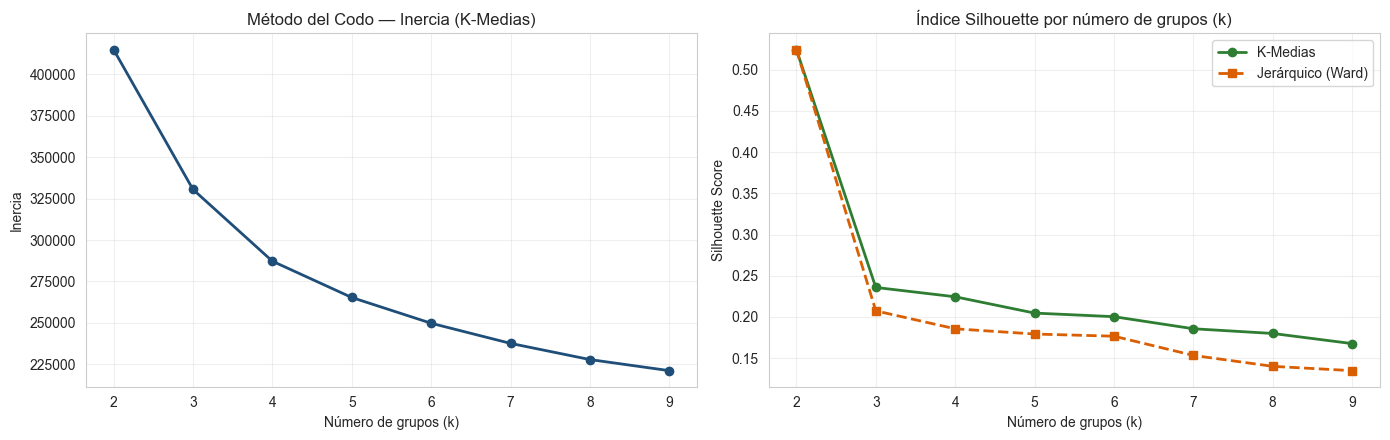

,k,Inercia_KMeans,Silhouette_KMeans,Silhouette_Ward
0,2,415019.0,0.5244,0.5244
1,3,330571.0,0.2358,0.2074
2,4,287249.0,0.2245,0.1856
3,5,265337.0,0.2047,0.1793
4,6,249782.0,0.2004,0.1767
5,7,237625.0,0.1857,0.1534
6,8,227858.0,0.1800,0.1401
7,9,221163.0,0.1677,0.1349


In [19]:
# Preparación exclusiva para agrupamiento (SIN targets ni variables monetarias)
CLUST_COLS = ATRIBUTOS_JUEGO + ["Height_cm", "Weight_lbs", "Age", "Weak Foot", "Skill Moves"]

pipe_clust = Pipeline([
    ("imp", SimpleImputer(strategy="median")),
    ("esc", StandardScaler())
])
X_clust = pipe_clust.fit_transform(df_reg[CLUST_COLS])

# Muestra fija para calcular Silhouette rápido y correr Jerárquico sin desbordar RAM
rng_c = np.random.default_rng(SEMILLA)
idx_muestra = rng_c.choice(len(X_clust), size=3000, replace=False)
X_muestra = X_clust[idx_muestra]

ks = range(2, 10)
inercias = []
sil_kmeans = []
sil_ward = []

for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA)
    lbl_km = km.fit_predict(X_clust)
    inercias.append(km.inertia_)
    sil_kmeans.append(silhouette_score(X_muestra, lbl_km[idx_muestra]))

    ward = AgglomerativeClustering(n_clusters=k, linkage="ward")
    lbl_w = ward.fit_predict(X_muestra)
    sil_ward.append(silhouette_score(X_muestra, lbl_w))

# Gráficos de selección de k
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].plot(list(ks), inercias, "o-", color="#1f4e79", lw=2)
axes[0].set_title("Método del Codo — Inercia (K-Medias)")
axes[0].set_xlabel("Número de grupos (k)")
axes[0].set_ylabel("Inercia")
axes[0].grid(alpha=0.3)

axes[1].plot(list(ks), sil_kmeans, "o-", color="#2e7d32", lw=2, label="K-Medias")
axes[1].plot(list(ks), sil_ward, "s--", color="#d95f02", lw=2, label="Jerárquico (Ward)")
axes[1].set_title("Índice Silhouette por número de grupos (k)")
axes[1].set_xlabel("Número de grupos (k)")
axes[1].set_ylabel("Silhouette Score")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

res_k = pd.DataFrame({
    "k": list(ks),
    "Inercia_KMeans": np.round(inercias, 0),
    "Silhouette_KMeans": np.round(sil_kmeans, 4),
    "Silhouette_Ward": np.round(sil_ward, 4)
})
display(res_k)

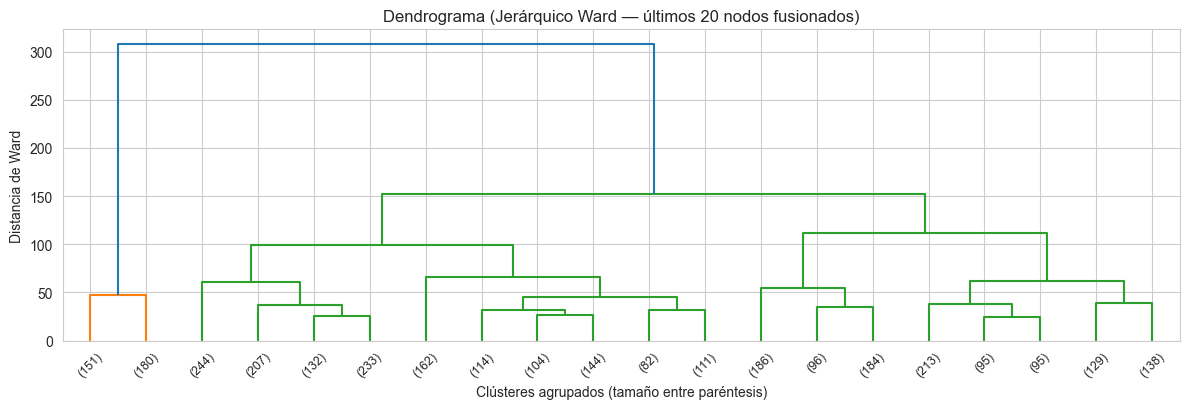

In [20]:
# Dendrograma truncado (Jerárquico Ward sobre muestra) para apoyar la lectura visual de k
Z = linkage(X_muestra, method="ward")
fig, ax = plt.subplots(figsize=(12, 4.2))
dendrogram(Z, truncate_mode="lastp", p=20, leaf_rotation=45, leaf_font_size=9, ax=ax)
ax.set_title("Dendrograma (Jerárquico Ward — últimos 20 nodos fusionados)")
ax.set_xlabel("Clústeres agrupados (tamaño entre paréntesis)")
ax.set_ylabel("Distancia de Ward")
plt.tight_layout()
plt.show()

Concordancia K-Medias vs. Jerárquico (Ward) con k=4 -> Adjusted Rand Index (ARI) = 0.4488
Tamaño de cada grupo en K-Medias:


,Jugadores
Cluster_KM,
0,5290
1,5820
2,4808
3,1989


,Age,Height_cm,Finishing,ShortPassing,Dribbling,SprintSpeed,Marking,SlidingTackle,GKDiving,Strength
Cluster_KM,,,,,,,,,,
0,24.6,183.7,32.3,57.6,48.8,61.9,61.7,62.5,10.5,71.2
1,27.2,179.1,58.5,70.4,69.3,70.3,56.4,54.5,10.7,67.3
2,22.8,178.3,58.5,58.8,63.1,72.0,33.6,29.4,10.3,58.4
3,26.0,188.2,12.0,27.3,13.8,38.7,15.2,14.1,65.3,60.6


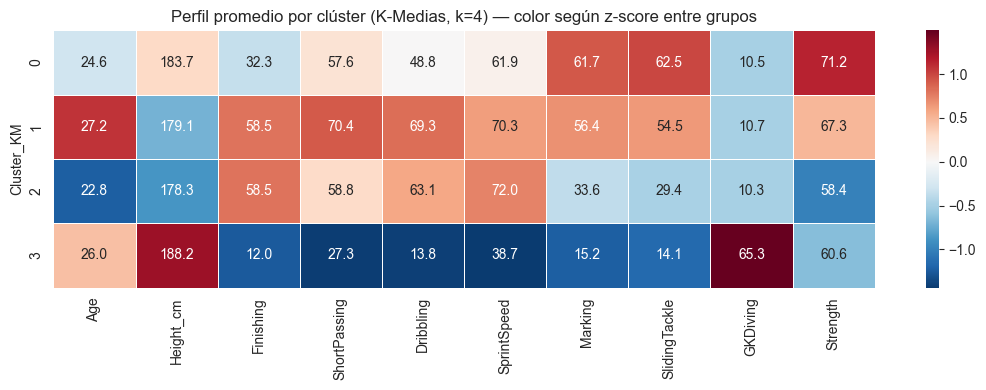

In [21]:
# K_OPT = 4: justificación (codo + Silhouette + dendrograma + interpretabilidad) en la lectura posterior
K_OPT = 4

km_final = KMeans(n_clusters=K_OPT, n_init=20, random_state=SEMILLA)
df_reg["Cluster_KM"] = km_final.fit_predict(X_clust)

ward_final = AgglomerativeClustering(n_clusters=K_OPT, linkage="ward")
lbl_ward_m = ward_final.fit_predict(X_muestra)

ari = adjusted_rand_score(df_reg["Cluster_KM"].iloc[idx_muestra], lbl_ward_m)
print(f"Concordancia K-Medias vs. Jerárquico (Ward) con k={K_OPT} -> Adjusted Rand Index (ARI) = {ari:.4f}")
print("Tamaño de cada grupo en K-Medias:")
display(df_reg["Cluster_KM"].value_counts().sort_index().to_frame("Jugadores"))

# Perfil de variables clave por clúster para ponerles nombre de negocio
vars_perfil = ["Age", "Height_cm", "Finishing", "ShortPassing", "Dribbling", "SprintSpeed", "Marking", "SlidingTackle", "GKDiving", "Strength"]
perfil_clusters = df_reg.groupby("Cluster_KM")[vars_perfil].mean().round(1)
display(perfil_clusters)

# Heatmap estandarizado de perfiles por clúster
perfil_z = (perfil_clusters - perfil_clusters.mean()) / perfil_clusters.std()
fig, ax = plt.subplots(figsize=(11, 4))
sns.heatmap(perfil_z, annot=perfil_clusters, fmt=".1f", cmap="RdBu_r", center=0, ax=ax, linewidths=0.5)
ax.set_title(f"Perfil promedio por clúster (K-Medias, k={K_OPT}) — color según z-score entre grupos")
plt.tight_layout()
plt.show()

#### Nombres de negocio para los grupos

* **Grupo 0 — Defensas físicos y marcadores** (5.290 jugadores): los más fuertes (`Strength` ≈ 71) y altos entre los jugadores de campo (≈ 184 cm), con la marca y la entrada más altas (`Marking` ≈ 62, `SlidingTackle` ≈ 63) y casi sin definición (`Finishing` ≈ 32). Mediana de valor ≈ €475 mil.
* **Grupo 1 — Mediocampistas completos y de experiencia** (5.820): los de más edad (≈ 27 años) y con el mejor pase corto (≈ 70) y regate (≈ 69), buena velocidad y definición media; es el grupo más heterogéneo y de **mayor valor** (mediana ≈ €2,3 M). Funciona como el perfil "polivalente" de la plantilla.
* **Grupo 2 — Atacantes jóvenes y veloces** (4.808): los más jóvenes (≈ 23 años) y rápidos (`SprintSpeed` ≈ 72), con buena definición (≈ 58) y muy baja marca (≈ 34). Mediana de valor ≈ €525 mil.
* **Grupo 3 — Porteros** (1.989): `GKDiving` ≈ 65 frente a ≈ 10 en los demás grupos, y habilidades de campo mínimas; los más altos (≈ 188 cm). Mediana de valor ≈ €375 mil.

In [22]:
# Cruce de los clústeres (K-Medias) con los DOS OBJETIVOS (Position_Group y Value)
cruce_pos = pd.crosstab(df_reg["Cluster_KM"], df_reg["Position_Group"], normalize="index") * 100
print("=== CRUCE 1: Clúster vs. Position_Group (% por fila) ===")
display(cruce_pos.round(1))

resumen_val = df_reg.groupby("Cluster_KM")["Value"].agg(
    jugadores="count",
    mediana_EUR="median",
    media_EUR="mean",
    p25_EUR=lambda s: np.percentile(s, 25),
    p75_EUR=lambda s: np.percentile(s, 75)
}).round(0)
print("=== CRUCE 2: Clúster vs. Value (€) ===")
display(resumen_val)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.heatmap(cruce_pos, annot=True, fmt=".1f", cmap="YlGnBu", ax=axes[0], linewidths=0.5)
axes[0].set_title("Cruce Clúster vs. Position_Group (% dentro de cada clúster)")
axes[0].tick_params(axis="x", rotation=35)

sns.boxplot(data=df_reg, x="Cluster_KM", y=np.log10(df_reg["Value"]), palette="Set2", ax=axes[1])
axes[1].set_title("Distribución de log10(Value) por Clúster")
axes[1].set_xlabel("Clúster (K-Medias)")
axes[1].set_ylabel("log10(Value en €)")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

SyntaxError: closing parenthesis '}' does not match opening parenthesis '(' on line 6 (3963319619.py, line 12)

#### Lectura e interpretación — Agrupamiento y cruce con los objetivos

**1. Justificación de $k$ y comparación K-Medias vs. Jerárquico.** El Silhouette es máximo en $k=2$ (≈ 0,52 en ambos métodos), pero ese corte solo separa porteros de jugadores de campo: el dendrograma lo confirma (la primera fusión, a distancia ≈ 310, aísla un bloque de unos 330 jugadores de la muestra, los porteros). Un $k=2$ es demasiado grueso para *scouting*. A partir de $k=3$ el Silhouette cae a ≈ 0,24 y se mantiene en ≈ 0,22 con $k=4$, mientras que la inercia baja con fuerza hasta $k=4$ (≈ −84 mil de 2 a 3, ≈ −43 mil de 3 a 4) y después casi se aplana (≈ −22 mil de 4 a 5). Se escoge **$k=4$** como el primer valor después del corte trivial donde el codo se suaviza y que da grupos interpretables (porteros, defensas, mediocampistas, atacantes). Con un Silhouette ≈ 0,22 la estructura es **débil**: los grupos son una segmentación útil, no clases naturales bien separadas. K-Medias y Ward coinciden de forma moderada (ARI ≈ 0,45): los porteros son el mismo bloque en ambos, y la discrepancia está en cómo se reparten los jugadores de campo.

**2. Cruce con `Position_Group`.** Los **porteros se separan limpiamente** sin usar etiquetas (el Grupo 3 es 100 % `Portero` y no contiene otra posición). El Grupo 0 es casi todo defensivo (≈ 53 % `Defensas`, ≈ 27 % `Laterales`, ≈ 11 % `Medio centro defensivo`). El Grupo 2 concentra ataque (≈ 39 % `Delanteros`, ≈ 11 % `Extremos`, ≈ 11 % `Medio centro ofensivo`) pero también un 36 % de `Medio centro puro`. El Grupo 1 **mezcla posiciones** (ninguna supera el 38 %: `Medio centro puro`, `Laterales`, `Medio centro defensivo`, `Delanteros`…). Esto conecta con la clasificación: `Extremos` y `Medio centro ofensivo` no tienen un grupo propio, se reparten entre los grupos 1 y 2, y por eso el clasificador los confunde.

**3. Cruce con `Value` ("Diferencia no es separación").** Las medianas difieren (Grupo 1 ≈ €2,3 M frente a ≈ €0,4–0,5 M de los otros tres), pero en el boxplot los grupos **no separan jugadores baratos de caros**: las cajas de los grupos 0, 2 y 3 son casi idénticas, la caja del Grupo 1 solo se desplaza hacia arriba y los bigotes de los cuatro grupos cubren casi todo el rango de valores (hay estrellas en todos, y la media del Grupo 3 es ≈ €1,6 M con mediana ≈ €0,4 M). Pertenecer a un grupo no basta para tasar a un jugador: el valor lo determinan sobre todo `Overall`, `Potential` y `Age`, que el agrupamiento (hecho con perfil de juego) no aísla.

## 7. Conclusiones para la gerencia (base para la presentación de negocio)

**El problema.** El club quiere (1) saber en qué puesto juega cada candidato sin revisar miles de fichas y (2) tener una primera tasación en euros antes de negociar.

**1. Qué preparación y qué modelo pondríamos a trabajar**
* **Para identificar el puesto:** un modelo sencillo y explicable (regresión logística), con los datos tal como vienen y las categorías (pie, ritmo de trabajo, tipo de cuerpo) separadas en columnas independientes. Varios modelos más complejos rindieron igual dentro del margen de error, así que elegimos el que se puede explicar jugador por jugador.
* **Para dar una primera tasación:** un conjunto de árboles de decisión (Gradient Boosting), con los datos tal como vienen y las categorías separadas. Escalar los datos o ponerles códigos numéricos a las categorías no cambió el resultado de forma apreciable; ese tipo de modelo es mucho mejor que los modelos lineales y que el de "vecinos más cercanos".

**2. Qué consigue el club**
* **Puesto:** de cada 100 jugadores nuevos, unos 78 quedan bien ubicados. Porteros, defensas y delanteros se reconocen casi siempre (cerca de 9 de cada 10 o más). Para preseleccionar delanteros exigimos más seguridad que la mitad de las veces (76 %): en una prueba de 3.630 jugadores esto evita 31 preselecciones equivocadas, a cambio de dejar pasar 59 delanteros reales más; conviene solo si fichar mal cuesta bastante más que perder una opción (lo supusimos en 3 a 1).
* **Tasación:** en jugadores que el modelo no vio, la tasación se acerca al valor de mercado en unos €110 mil en promedio y el error típico es del 3 % del valor; solo 1 de cada 200 jugadores se desvía más de 30 %.
* **Perfiles de plantilla:** sin mirar puestos ni precios, el análisis encuentra cuatro grupos: porteros, defensas físicos, atacantes jóvenes y veloces, y mediocampistas completos y de más edad; este último grupo concentra los jugadores de mayor valor.

**3. En qué NO hay que creerle al modelo**
* **Jugadores híbridos o de posiciones vecinas** (extremos, volantes ofensivos, laterales con perfil de central): el modelo los reconoce mal (solo 1 de cada 7 extremos) y se equivoca con total seguridad, así que su "confianza" no sirve de alarma.
* **Tasación de estrellas:** en jugadores de élite el error en euros es de millones (de €3 M a €9 M en los peores casos) aunque en proporción sea moderado; tiende a **sobrevalorar jóvenes con mucho potencial** y a **subvalorar veteranos y porteros**.
* **Casi todo el valor lo explican dos o tres datos** (calidad actual, potencial y edad): el modelo no ve lesiones, video, contexto de mercado ni necesidades del club.
* **Los grupos no son una tabla de precios:** pertenecer a un grupo no dice si un jugador es barato o caro, y la separación entre grupos es débil.
* **Alcance:** los 240 jugadores sin contrato (valor 0) no se tasaron, y los datos corresponden a un único videojuego/temporada, no a mediciones de rendimiento reales.